# Q3 — Les liaisons TGV ont-elles des « profils de ponctualité » ?

> **En bref, pour l'équipe**
>
> 1. **Les données brutes contiennent des valeurs impossibles** (comptages négatifs, retards
>    moyens de −472 min, liaisons « non circulées » en plein confinement). Elles sont corrigées
>    champ par champ, sans jeter les lignes : on ne perd plus que 73 lignes sur 12 907, toutes
>    des mois où la liaison ne circulait pas.
> 2. **2025 est une année à part dans la source** : trou de publication en début d'année, lignes
>    doublées en été, et une colonne « retards > 30 min » qui change visiblement de définition.
>    À corriger dans le pipeline (section I.5 bis).
> 3. **Plus un trajet est long, plus il a de chances d'arriver avec plus de 15 min de retard**
>    (de ≈ 5 % pour 1 h à ≈ 19 % pour 7 h). Sans en tenir compte, un clustering se contente de
>    séparer liaisons courtes et longues : c'est ce qu'on obtenait avant.
> 4. **Une fois la durée et les redondances retirées**, les liaisons se distinguent surtout par
>    un **arbitrage fréquence / gravité** : certaines sont *souvent* en retard mais pas longtemps
>    (et annulent un peu plus), d'autres *moins souvent* mais plus longtemps.
> 5. **Ces groupes ne sont pas des « familles » nettement séparées** : c'est un continuum que
>    l'on découpe (silhouette 0,26), mais le découpage est stable et meilleur que le hasard.
> 6. **Le traitement des grèves et confinements change les profils** (accord de seulement 62 %
>    entre « tout garder » et « exclure les événements documentés ») : ce choix doit être visible
>    dans l'app.

# Partie I - Analyse des données et analyse univariée

> **Avant le clustering.** Un clustering calcule des distances entre
> liaisons. Une valeur impossible, un zéro qui cache un manquant ou une colonne mal typée
> déplacent ces distances **sans aucun message d'erreur**. La session 3 du cours le résume :
> *the mechanism matters more than the rate*.

**Objectifs**
1. Vérifier le **typage** : type informatique vs type statistique de chaque colonne.
2. Recenser les **valeurs impossibles ou suspectes** (négatifs, incohérences logiques, zéros déguisés).
3. Prendre et **documenter des décisions** (elles alimentent la datasheet).
4. Faire l'**analyse univariée** complète : quantitative, qualitative, temporelle.

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)
SEED = 42  # reproducibility (course rule)

RAW_PATH = Path("../data/raw/regularite-mensuelle-tgv-aqst.csv")

In [2]:
raw = pd.read_csv(RAW_PATH, sep=";", encoding="utf-8-sig")
print(raw.shape)
raw.head(3)

(12907, 26)


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Commentaire retards à l'arrivée,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.2478,3.6932,NaN,147,28.4367,6.5111,NaN,110,6.5111,44,8,36.1345,31.0924,10.9244,15.9664,5.0420,0.8403
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.4800,4.5671,NaN,105,18.0490,5.3635,"Ce mois-ci, l'OD a été touchée par les inciden...",32,5.3635,9,4,20.0000,35.0000,16.6667,16.6667,8.3333,3.3333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.2397,0.2863,NaN,19,24.7368,2.9381,NaN,11,2.9381,6,1,22.2222,27.7778,16.6667,16.6667,5.5556,11.1111


## I.2 Audit du typage : type informatique vs type statistique

Session 1 : *types in statistics ≠ types in programming*. Pandas devine un type de stockage
(`int64`, `float64`, `object`/`str`). Nous, on a besoin du **type statistique** pour savoir
quelles opérations ont un sens :

| Type statistique | Opérations légitimes | Exemple ici |
|---|---|---|
| Nominal | comptage, mode | gare, service |
| Ordinal / temporel | tri, comparaisons, écarts | mois |
| Comptage (entier ≥ 0) | sommes, ratios | trains prévus, annulés, en retard |
| Continu | moyenne, quantiles | durée, retard moyen |
| Proportion / composition | moyenne **pondérée** uniquement, somme = 100 | % de causes |
| Texte libre | lecture qualitative | commentaires |

In [3]:
EXPECTED = {
    "Date": "temporal (month)",
    "Service": "nominal",
    "Gare de départ": "nominal",
    "Gare d'arrivée": "nominal",
    "Durée moyenne du trajet": "continuous (min)",
    "Commentaire annulations": "free text",
    "Commentaire retards au départ": "free text",
    "Commentaire retards à l'arrivée": "free text",
}
for col in raw.columns:
    if col.startswith(("Nombre",)):
        EXPECTED[col] = "count (int >= 0)"
    elif col.startswith("Prct"):
        EXPECTED[col] = "proportion (0-100)"
    elif col.startswith("Retard moyen"):
        EXPECTED[col] = "continuous (min)"

audit = pd.DataFrame(
    {
        "pandas_dtype": raw.dtypes.astype(str),
        "expected_type": pd.Series(EXPECTED),
        "n_unique": raw.nunique(),
        "pct_missing": raw.isna().mean().round(4),
        "example": raw.iloc[0],
    }
)
audit

,pandas_dtype,expected_type,n_unique,pct_missing,example
Commentaire annulations,float64,free text,0,1.0000,NaN
Commentaire retards au départ,float64,free text,0,1.0000,NaN
Commentaire retards à l'arrivée,str,free text,302,0.9459,NaN
Date,str,temporal (month),105,0.0000,2018-01
Durée moyenne du trajet,int64,continuous (min),411,0.0000,141
Gare d'arrivée,str,nominal,59,0.0000,PARIS MONTPARNASSE
Gare de départ,str,nominal,59,0.0000,BORDEAUX ST JEAN
Nombre de circulations prévues,int64,count (int >= 0),908,0.0000,870
Nombre de trains annulés,int64,count (int >= 0),192,0.0000,5
Nombre de trains en retard au départ,int64,count (int >= 0),460,0.0000,289


📌 **À retenir** — le typage de stockage est **globalement correct** : tous les comptages sont
des entiers, retards et parts des décimaux. Il y a deux vrais problèmes de type : la date est
stockée en texte (on la convertit en mois), et les commentaires sont presque vides (deux colonnes
le sont à 100 %).

Les problèmes repérés par l'équipe sont donc surtout des problèmes de **contenu** : des valeurs
impossibles dans des colonnes bien typées. C'est plus dangereux qu'un mauvais type, parce que
pandas calcule sans broncher une moyenne qui contient −472 minutes. D'où la section I.5.

**À lire dans ce tableau**
- `Date` est stockée en texte : on ne peut ni trier chronologiquement de façon sûre, ni extraire
  le mois calendaire. → conversion en `Period[M]`.
- Une colonne de **comptage** stockée en `float64` signale souvent des `NaN` ou des valeurs
  non entières ; une colonne numérique en `object`/`str` signale du texte parasite (virgule
  décimale, espace, « ND »…). La cellule suivante le teste.
- Les commentaires sont quasi vides : inutilisables comme variables.

In [4]:
# Which numeric-looking columns fail a strict numeric conversion?
num_like = [
    c
    for c, t in EXPECTED.items()
    if t.startswith(("count", "continuous", "proportion"))
]
for col in num_like:
    converted = pd.to_numeric(raw[col], errors="coerce")
    new_nan = converted.isna().sum() - raw[col].isna().sum()
    non_int = 0
    if EXPECTED[col].startswith("count"):
        non_int = ((converted.dropna() % 1) != 0).sum()
    if new_nan or non_int:
        print(f"{col!r}: {new_nan} values not numeric, {non_int} non-integer counts")
print("Conversion check done.")

Conversion check done.


## I.3 Renommage et typage

On renomme en `snake_case` (plus pratique) et on applique les types attendus. **Aucune
correction de valeur ici** : on corrige le *contenant*, pas le *contenu*.

In [5]:
_K_DELAY15 = "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"
_K_STATION = "Prct retard pour cause gestion en gare et réutilisation de matériel"
COL_MAP = {
    "Date": "date",
    "Service": "service",
    "Gare de départ": "departure",
    "Gare d'arrivée": "arrival",
    "Durée moyenne du trajet": "trip_duration_min",
    "Nombre de circulations prévues": "trains_planned",
    "Nombre de trains annulés": "trains_cancelled",
    "Commentaire annulations": "comment_cancellations",
    "Nombre de trains en retard au départ": "late_departure",
    "Retard moyen des trains en retard au départ": "mean_delay_late_dep",
    "Retard moyen de tous les trains au départ": "mean_delay_all_dep",
    "Commentaire retards au départ": "comment_departure",
    "Nombre de trains en retard à l'arrivée": "late_arrival",
    "Retard moyen des trains en retard à l'arrivée": "mean_delay_late_arr",
    "Retard moyen de tous les trains à l'arrivée": "mean_delay_all_arr",
    "Commentaire retards à l'arrivée": "comment_arrival",
    "Nombre trains en retard > 15min": "late_15min",
    _K_DELAY15: "delay_15_flight_unclear",
    "Nombre trains en retard > 30min": "late_30min",
    "Nombre trains en retard > 60min": "late_60min",
    "Prct retard pour causes externes": "pct_cause_external",
    "Prct retard pour cause infrastructure": "pct_cause_infra",
    "Prct retard pour cause gestion trafic": "pct_cause_traffic",
    "Prct retard pour cause matériel roulant": "pct_cause_rolling_stock",
    _K_STATION: "pct_cause_station_mgmt",
    "Prct retard pour cause prise en compte voyageurs "
    "(affluence, gestions PSH, correspondances)": "pct_cause_passengers",
}
COUNT_COLS = [
    "trains_planned",
    "trains_cancelled",
    "late_departure",
    "late_arrival",
    "late_15min",
    "late_30min",
    "late_60min",
]
DELAY_COLS = [
    "mean_delay_late_dep",
    "mean_delay_all_dep",
    "mean_delay_late_arr",
    "mean_delay_all_arr",
]
PCT_COLS = [c for c in COL_MAP.values() if c.startswith("pct_cause_")]

df = raw.rename(columns=COL_MAP)
df["date"] = pd.to_datetime(df["date"].astype(str)).dt.to_period("M")
for col in ("service", "departure", "arrival"):
    df[col] = df[col].astype(str).str.strip().str.upper()
num_cols = [
    "trip_duration_min",
    *COUNT_COLS,
    *DELAY_COLS,
    *PCT_COLS,
    "delay_15_flight_unclear",
]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
df["route"] = df["departure"] + " → " + df["arrival"]
df["trains_run"] = (
    df["trains_planned"] - df["trains_cancelled"]
)  # NOT clipped on purpose
df.dtypes

date                       period[M]
service                          str
departure                        str
arrival                          str
trip_duration_min              int64
trains_planned                 int64
trains_cancelled               int64
comment_cancellations        float64
late_departure                 int64
mean_delay_late_dep          float64
mean_delay_all_dep           float64
comment_departure            float64
late_arrival                   int64
mean_delay_late_arr          float64
mean_delay_all_arr           float64
comment_arrival                  str
late_15min                     int64
delay_15_flight_unclear      float64
late_30min                     int64
late_60min                     int64
pct_cause_external           float64
pct_cause_infra              float64
pct_cause_traffic            float64
pct_cause_rolling_stock      float64
pct_cause_station_mgmt       float64
pct_cause_passengers         float64
route                            str
t

⚠️ **Pourquoi on ne fait pas `.clip(lower=0)` sur `trains_run`** (ce que faisait la v1) :
`clip` transforme une valeur *impossible* (−3 trains circulés) en une valeur *plausible* (0
train circulé, soit 100 % d'annulation). L'erreur disparaît de la vue mais reste dans les
calculs. Une valeur impossible doit être **signalée**, puis traitée par une décision explicite.

## I.4 Clé et doublons

Une ligne doit correspondre à un unique triplet *(mois, service, liaison)*. Sinon, toute
somme par liaison compte des trains deux fois.

In [6]:
key = ["date", "service", "departure", "arrival"]
dup = df.duplicated(subset=key, keep=False)
print(f"Duplicated keys: {dup.sum()} rows")
print(
    f"Routes present in several services: "
    f"{(df.groupby('route')['service'].nunique() > 1).sum()}"
)
df[dup].sort_values(key).head(10)

Duplicated keys: 0 rows
Routes present in several services: 16


,date,service,departure,arrival,trip_duration_min,trains_planned,trains_cancelled,comment_cancellations,late_departure,mean_delay_late_dep,mean_delay_all_dep,comment_departure,late_arrival,mean_delay_late_arr,mean_delay_all_arr,comment_arrival,late_15min,delay_15_flight_unclear,late_30min,late_60min,pct_cause_external,pct_cause_infra,pct_cause_traffic,pct_cause_rolling_stock,pct_cause_station_mgmt,pct_cause_passengers,route,trains_run


In [7]:
# A route can change "service" label over time: is (month, route) still unique?
dup_route_month = df.duplicated(subset=["date", "route"], keep=False)
print(f"(month, route) duplicates: {dup_route_month.sum()} rows")
switching = df.groupby("route")["service"].nunique()
print(f"Routes with several service labels over time: {(switching > 1).sum()}")
df[df["route"].isin(switching[switching > 1].index)].groupby(["route", "service"])[
    "date"
].agg(["min", "max", "count"]).head(12)

(month, route) duplicates: 84 rows
Routes with several service labels over time: 16


min      max  count
route                                  service                               
BARCELONA → PARIS LYON                 INTERNATIONAL  2018-01  2025-09     93
                                       NATIONAL       2025-10  2026-09     12
BELLEGARDE (AIN) → PARIS LYON          INTERNATIONAL  2025-07  2025-09      3
                                       NATIONAL       2018-01  2026-09    105
CHAMBERY CHALLES LES EAUX → PARIS LYON INTERNATIONAL  2025-07  2025-09      3
                                       NATIONAL       2018-01  2026-09    105
DIJON VILLE → PARIS LYON               INTERNATIONAL  2025-07  2025-09      3
                                       NATIONAL       2018-01  2026-09    105
LYON PART DIEU → MARSEILLE ST CHARLES  INTERNATIONAL  2025-07  2025-09      3
                                       NATIONAL       2018-01  2026-09    105
MACON LOCHE → PARIS LYON               INTERNATIONAL  2025-07  2025-09      3
                                       NATIONAL       2018-01  2026-09    105

📌 **À retenir** — aucune clé *(mois, service, liaison)* n'est dupliquée, mais deux phénomènes
apparaissent :

- **16 liaisons changent de libellé de service** au fil du temps. Exemple : Barcelone → Paris
  Lyon est « International » jusqu'en septembre 2025, puis « National ». C'est un **reclassement**,
  pas un nouveau trafic : l'identité d'une liaison est donc `départ → arrivée`, quel que soit le
  service.
- **84 lignes forment 42 couples *(mois, liaison)* en double**, presque tous entre **juillet et
  septembre 2025**. Exemples : Bellegarde, Chambéry, Dijon ou Mâcon → Paris Lyon, Lyon → Marseille,
  qui ont alors une ligne « National » (comme d'habitude) **et** une ligne « International ». Comme
  les calculs somment par liaison, les deux lignes s'additionnent : c'est juste si ce sont des
  trains différents, faux si les mêmes trains sont déclarés deux fois.
  **À vérifier dans le pipeline** : comparer le nombre de trains prévus des deux lignes (une ligne
  « International » avec peu de trains = trains supplémentaires, donc on additionne).

## I.5 Audit des valeurs impossibles ou suspectes

On écrit chaque règle métier comme un test vectorisé. Trois familles :

- **Impossible** : contredit la définition (un comptage négatif, plus d'annulés que de prévus).
- **Incohérence logique** : contredit une autre colonne. Exemple clé : le seuil « composite »
  de la colonne *en retard à l'arrivée* vaut 5, 10 ou 15 min selon la durée, donc **tout train
  en retard de plus de 15 min est aussi compté « en retard »** :
  $L^{15} \le L^{\text{arr}}$. De même $L^{60} \le L^{30} \le L^{15}$.
- **Manquant déguisé** (session 3 : *a 0 can be a disguised missing value*) : un « retard moyen
  des trains en retard » égal à 0 quand **aucun** train n'est en retard n'est pas un retard nul,
  c'est une valeur **qui n'existe pas**.

In [8]:
pct_sum = df[PCT_COLS].sum(axis=1)
RULES = {
    # Impossible values
    **{f"{c} < 0": df[c] < 0 for c in COUNT_COLS},
    "trains_planned == 0": df["trains_planned"] == 0,
    "trains_cancelled > trains_planned": df["trains_cancelled"] > df["trains_planned"],
    "trip_duration_min <= 0": df["trip_duration_min"] <= 0,
    "mean_delay_late_arr < 0": df["mean_delay_late_arr"] < 0,
    "mean_delay_all_arr < -15": df["mean_delay_all_arr"] < -15,
    "mean_delay_all_dep < -15": df["mean_delay_all_dep"] < -15,
    "pct outside [0, 100]": ((df[PCT_COLS] < 0) | (df[PCT_COLS] > 100)).any(axis=1),
    # Logical inconsistencies (nested thresholds: L60 <= L30 <= L15 <= Larr <= run)
    "late_arrival > trains_run": df["late_arrival"] > df["trains_run"],
    "late_departure > trains_run": df["late_departure"] > df["trains_run"],
    "late_15min > trains_run": df["late_15min"] > df["trains_run"],
    "late_15min > late_arrival": df["late_15min"] > df["late_arrival"],
    "late_30min > late_15min": df["late_30min"] > df["late_15min"],
    "late_60min > late_30min": df["late_60min"] > df["late_30min"],
    "pct sum == 0 while late > 0": (df["late_arrival"] > 0) & (pct_sum == 0),
    "pct sum in ]0,95[ or > 105 while late > 0": (df["late_arrival"] > 0)
    & (pct_sum > 0)
    & ((pct_sum - 100).abs() > 5),
    "pct sum in [95,105] but != 100": (df["late_arrival"] > 0)
    & ((pct_sum - 100).abs() > 1)
    & ((pct_sum - 100).abs() <= 5),
    # Disguised missing values
    "mean_delay_late_arr == 0 while late == 0": (df["late_arrival"] == 0)
    & (df["mean_delay_late_arr"] == 0),
    "pct sum == 0 while late == 0": (df["late_arrival"] == 0) & (pct_sum == 0),
    "mean_delay_late_arr == 0 while late > 0": (df["late_arrival"] > 0)
    & (df["mean_delay_late_arr"] == 0),
    # Legitimate but surprising
    "mean_delay_all_arr in [-15, 0[": df["mean_delay_all_arr"].between(
        -15, 0, inclusive="left"
    ),
    "mean_delay_all_dep in [-15, 0[": df["mean_delay_all_dep"].between(
        -15, 0, inclusive="left"
    ),
    "trains_run == 0 (fully cancelled)": (df["trains_run"] == 0)
    & (df["trains_planned"] > 0),
}
rule_table = pd.DataFrame(
    {
        "n_rows": {name: int(mask.sum()) for name, mask in RULES.items()},
        "pct_rows": {name: mask.mean() for name, mask in RULES.items()},
    }
).sort_values("n_rows", ascending=False)
rule_table

,n_rows,pct_rows
late_60min > late_30min,354,0.0274
pct sum == 0 while late == 0,192,0.0149
mean_delay_late_arr == 0 while late == 0,192,0.0149
"mean_delay_all_dep in [-15, 0[",165,0.0128
"mean_delay_all_arr in [-15, 0[",111,0.0086
pct sum == 0 while late > 0,80,0.0062
trains_planned == 0,73,0.0057
trip_duration_min <= 0,73,0.0057
late_15min > trains_run,65,0.0050
late_departure > trains_run,64,0.0050


In [9]:
# Where are the impossible cancellations? Concentrated or scattered?
bad = df[RULES["trains_cancelled > trains_planned"]]
print(
    f"{len(bad)} rows, {bad['route'].nunique()} routes, {bad['date'].nunique()} months"
)
display(bad["date"].astype(str).value_counts().head(10).rename("rows per month"))
bad[["date", "route", "trains_planned", "trains_cancelled", "trains_run"]].head(10)

63 rows, 52 routes, 3 months


date
2020-04    50
2020-05     9
2020-06     4
Name: rows per month, dtype: int64

,date,route,trains_planned,trains_cancelled,trains_run
3406,2020-04,PARIS MONTPARNASSE → ST MALO,0,8,-8
3407,2020-04,PARIS MONTPARNASSE → TOURS,0,9,-9
3409,2020-04,NANTES → STRASBOURG,0,2,-2
3411,2020-04,PARIS NORD → DOUAI,0,12,-12
3412,2020-04,DUNKERQUE → PARIS NORD,0,15,-15
3414,2020-04,MARSEILLE ST CHARLES → TOURCOING,0,1,-1
3415,2020-04,LYON PART DIEU → MARNE LA VALLEE,0,19,-19
3416,2020-04,MARNE LA VALLEE → MARSEILLE ST CHARLES,0,14,-14
3417,2020-04,MARSEILLE ST CHARLES → MARNE LA VALLEE,0,13,-13
3418,2020-04,PARIS LYON → AIX EN PROVENCE TGV,0,17,-17


In [10]:
# Negative "mean delay of ALL trains": how negative? (early arrivals on average)
neg = df.loc[df["mean_delay_all_arr"] < 0, "mean_delay_all_arr"]
print(neg.describe())

count    122.0000
mean     -12.9090
std       52.2687
min     -472.6389
25%       -1.7600
50%       -0.6933
75%       -0.3203
max       -0.0006
Name: mean_delay_all_arr, dtype: float64


## I.5 bis — Que signifient concrètement ces violations ?

Une règle violée n'est pas forcément une « erreur » : c'est un **signal** qui demande une
explication. Voici chaque violation, de la plus lourde de conséquences à la plus bénigne.

| Règle violée | Lignes | Ce que ça veut dire | Si on ne fait rien |
|---|---:|---|---|
| `late_60min > late_30min` | 354 (2,7 %) | Impossible si les colonnes sont cumulatives (un train en retard de plus de 60 min l'est aussi de plus de 30). **Toutes ces lignes sont en 2025** : c'est un **changement de définition**, pas une faute de frappe (diagnostic ci-dessous) | Les retards graves de 2025 sont faux |
| `trains_planned == 0` | 73 | Liaison **absente du plan de transport** ce mois-là. 63 d'entre elles (avril à juin 2020) affichent quand même des annulations, comptées par rapport au plan initial d'avant le confinement | `trains_run` négatif, taux infinis |
| `trip_duration_min <= 0` | 73 | **Ce sont exactement les mêmes 73 lignes** : une durée nulle veut dire « la liaison n'a pas circulé », pas « durée inconnue » | Liaisons classées « courtes » à tort |
| `mean_delay_late_arr == 0` sans train en retard | 192 | **Manquant déguisé** : sans train en retard, la moyenne n'existe pas | Moyennes tirées vers 0 |
| Somme des causes = 0 alors que des trains sont en retard | 80 | Causes non renseignées | Parts de causes fausses |
| `late_15min > trains_run` | 65 | Plus de trains en retard que de trains circulés : presque toutes sont les lignes « liaison non circulée » ci-dessus | Taux > 100 % |
| `late_30min < 0` | 43 | Comptage négatif : impossible | Sommes sous-estimées |
| `mean_delay_late_arr == 0` avec des trains en retard | 38 | Des trains en retard, mais un retard moyen nul : impossible | Idem |
| `late_15min > late_arrival` | 31 (0,24 %) | Contredit l'hypothèse « *en retard à l'arrivée* = seuil composite ≤ 15 min ». Elle tient sur 99,76 % des lignes : on la garde | Quasi aucune |
| `mean_delay_all_* < −15` | 11 + 5 | Erreurs grossières (9 valeurs en dessous de −60 min, minimum −472) | Moyennes et variances écrasées |
| `mean_delay_all_* ∈ [−15, 0[` | 111 + 165 | **Légitime** : en moyenne, les trains sont arrivés un peu en avance (médiane −0,7 min) | Rien, on garde |

**Le principe** : avant, une seule valeur fausse faisait **exclure toute la ligne** (106 lignes
perdues). Or une ligne où seul `late_30min` est négatif contient des annulations et des retards
parfaitement valides. Désormais, on **invalide le champ, pas la ligne**.

In [12]:
# Diagnostic 1 — late_60 > late_30: data error or different definition?
v = df["late_60min"] > df["late_30min"]
print(f"{v.sum()} rows ({v.mean():.1%}) with late_60 > late_30")
by_year = v.groupby(df["date"].dt.year).agg(["sum", "mean"])
display(by_year.rename(columns={"sum": "rows", "mean": "share"}))
print("Top routes:")
display(v.groupby(df["route"]).sum().sort_values(ascending=False).head(8))

# Two competing definitions of the columns
cumulative_ok = (df["late_60min"] <= df["late_30min"]) & (
    df["late_30min"] <= df["late_15min"]
)
bins_ok = (df["late_30min"] + df["late_60min"]) <= df[
    "late_15min"
]  # if 30 = [30,60[ and 60 = [60,inf[
print(f"Rows consistent with 'cumulative' definition: {cumulative_ok.mean():.1%}")
print(f"Rows consistent with 'bins' definition      : {bins_ok.mean():.1%}")
print(f"Among violating rows, consistent with 'bins': {bins_ok[v].mean():.1%}")
print("Size of the excess (late_60 - late_30) on violating rows:")
print((df.loc[v, "late_60min"] - df.loc[v, "late_30min"]).describe())

354 rows (2.7%) with late_60 > late_30


,rows,share
date,,
2018,0,0.0000
2019,0,0.0000
2020,0,0.0000
2021,0,0.0000
2022,0,0.0000
2023,0,0.0000
2024,0,0.0000
2025,354,0.2369
2026,0,0.0000


Top routes:


route
AIX EN PROVENCE TGV → PARIS LYON          3
ANGERS SAINT LAUD → PARIS MONTPARNASSE    3
ANGOULEME → PARIS MONTPARNASSE            3
ANNECY → PARIS LYON                       3
ARRAS → PARIS NORD                        3
AVIGNON TGV → PARIS LYON                  3
BARCELONA → PARIS LYON                    3
BELLEGARDE (AIN) → PARIS LYON             3
dtype: int64

Rows consistent with 'cumulative' definition: 97.2%
Rows consistent with 'bins' definition      : 93.3%
Among violating rows, consistent with 'bins': 100.0%
Size of the excess (late_60 - late_30) on violating rows:
count   354.0000
mean     14.4294
std      10.5625
min       1.0000
25%       6.0000
50%      12.0000
75%      20.0000
max      69.0000
dtype: float64


📌 **Verdict du diagnostic 1 : la définition change en 2025.**

- Les 354 lignes en cause sont **toutes en 2025**, et elles représentent **24 % des lignes de
  cette année**. Les autres années : zéro.
- Elles sont **dispersées sur toutes les liaisons**, environ 3 par liaison (vraisemblablement les
  mêmes mois partout).
- L'excès n'est pas une petite faute de frappe : **12 trains en médiane** (jusqu'à 69).
- **100 % de ces lignes respectent la définition « par tranches »** : `late_30min` y compterait les
  trains en retard **entre 30 et 60 min**, et non plus tous ceux de plus de 30 min.

Conclusion : sur la période concernée de 2025, la SNCF publie probablement des **tranches**.
La bonne correction n'est donc pas d'effacer `late_60min` (ce que fait la décision D4 actuelle,
sur 311 valeurs), mais de **reconstruire le cumul** : `late_30_cumul = late_30 + late_60` sur les
mois concernés. Sinon, les retards de plus de 30 min de 2025 sont **sous-estimés pour toutes les
liaisons**, y compris celles qui ne déclenchent pas la règle.

**Impact sur la Q3** : modéré. L'erreur touche toutes les liaisons à peu près de la même façon,
sur environ 1 mois sur 7 de la période analysée. Les profils (qui sont relatifs) bougent peu, mais
les valeurs absolues de sévérité sont légèrement sous-estimées.
**Impact sur la Q1** : fort. Toute courbe d'évolution des retards graves montrerait une fausse
amélioration en 2025.

➡️ **Action pipeline** : repérer les mois exacts (`df.loc[df["late_60min"] > df["late_30min"],
"date"].value_counts()`), confirmer la définition sur le portail SNCF, puis appliquer la
reconstruction du cumul sur toute la période concernée.

2025 cumule d'ailleurs les anomalies : trou de publication en début d'année (section I.9), lignes
en double en été (section I.4), et ce changement de définition. C'est probablement une **refonte de
la publication** : à signaler dans la datasheet.

In [13]:
# Diagnostic 2 — impossible durations and cause shares
zero_d = df[df["trip_duration_min"] <= 0]
print(f"{len(zero_d)} rows with duration <= 0 on {zero_d['route'].nunique()} routes")
print(
    "Do those routes have a valid duration in other months?",
    df[df["route"].isin(zero_d["route"]) & (df["trip_duration_min"] > 0)][
        "route"
    ].nunique(),
    "routes yes",
)

late_rows = df[df["late_arrival"] > 0]
s = late_rows[PCT_COLS].sum(axis=1)
print("\nSum of cause shares when at least one train is late:")
print(
    pd.cut(
        s,
        [-0.1, 0.1, 95, 99.5, 100.5, 105, 1e9],
        labels=["0", "]0,95]", "]95,99.5]", "~100", "]100.5,105]", ">105"],
    )
    .value_counts()
    .sort_index()
)

# Diagnostic 3 — negative mean delay of ALL trains: two populations
neg = df.loc[df["mean_delay_all_arr"] < 0, "mean_delay_all_arr"]
print(
    "\nNegative mean_delay_all_arr:",
    pd.cut(neg, [-1e9, -60, -15, -5, 0]).value_counts().sort_index().to_dict(),
)

73 rows with duration <= 0 on 52 routes
Do those routes have a valid duration in other months? 52 routes yes

Sum of cause shares when at least one train is late:
0                 80
]0,95]             3
]95,99.5]          7
~100           12625
]100.5,105]        0
>105               0
Name: count, dtype: int64

Negative mean_delay_all_arr: {Interval(-1000000000.0, -60.0, closed='right'): 9, Interval(-60.0, -15.0, closed='right'): 2, Interval(-15.0, -5.0, closed='right'): 3, Interval(-5.0, 0.0, closed='right'): 108}


## I.6 Décisions et justification

Une décision se juge à trois questions : **quelle est la nature de l'anomalie ? que fait chaque
option à l'analyse ? peut-on vérifier que le résultat n'en dépend pas ?**

**Principe général : on invalide le champ, pas la ligne.** Les taux sont ensuite calculés en
« ratio de sommes **sur paires valides** » : pour un taux $\sum L / \sum C$, on ne garde que les
mois où $L$ **et** $C$ sont tous les deux valides.

| # | Anomalie | Décision | Effet observé |
|---|---|---|---:|
| D1 | Comptage < 0 | → `NaN` **sur ce champ seulement** | 43 valeurs (`late_30min`) |
| D2 | `trains_planned == 0` (liaison non circulée) | **Ligne retirée** | 73 lignes |
| D3 | Annulés > prévus avec prévus > 0 | `trains_cancelled` → `NaN` | 0 (tout était déjà réglé par D2) |
| D4 | Seuils non emboîtés | Champ fautif (et ceux qui en dépendent) → `NaN` | 311 valeurs `late_60min`, 3 `late_30min`, 2 `late_15min` |
| D5 | Durée ≤ 0 | Médiane de la liaison | 0 (les 73 durées nulles disparaissent avec D2) |
| D6 | Retard moyen des trains en retard indéfini ou ≤ 0 | → `NaN` | 159 à l'arrivée, 57 au départ |
| D7 | Causes : somme nulle ou incohérente / proche de 100 | → `NaN` / renormalisées | 202 / 7 |
| D8 | Retard moyen de **tous** les trains < −15 min | → `NaN` | 11 à l'arrivée, 5 au départ |
| D9 | Commentaires, colonne « > 15 (si concurrencée par vol) » | Supprimées | 4 colonnes |
| D10 | `trains_run == 0` | Gardé pour les annulations | 0 |

**Résultat** : on garde **12 834 lignes sur 12 907**. Avant, on en gardait 12 801, en ayant
jeté des lignes qui contenaient des mesures valides.

⚠️ **D4 n'est pas la bonne décision pour `late_60min` en 2025** (voir le verdict du diagnostic 1) :
il faut reconstruire le cumul plutôt qu'effacer. Les résultats de ce notebook utilisent encore
D4 ; la correction est à faire dans le pipeline.

**Contrôle de robustesse** : section II.10.

In [14]:
# ── Quality decisions v3: invalidate the FIELD, not the row ───────────────────
COMMENT_COLS = ["comment_cancellations", "comment_departure", "comment_arrival"]
MIN_PLAUSIBLE_MEAN_DELAY_ALL = (
    -15.0
)  # minutes; below = data error, above = early trains (legit)
PCT_TOLERANCE = 5.0  # |sum of cause shares - 100| tolerated before renormalising


def apply_decisions(raw_typed: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply decisions D1-D10 and return (clean data, report of what changed).

    Principle: an impossible value invalidates the field concerned (-> NaN), not the
    whole row, so that the other valid measures of that month are kept. Rates are then
    computed only on rows where numerator AND denominator are valid.
    """
    df = raw_typed.copy()
    report: dict[str, int] = {}

    def invalidate(mask: pd.Series, cols: list[str], code: str) -> None:
        report[code] = int(mask.sum())
        df.loc[mask, cols] = np.nan

    # D2: route absent from the (COVID) adapted plan: planned = 0 -> row dropped
    absent = df["trains_planned"] == 0
    report["D2 rows dropped (planned == 0)"] = int(absent.sum())
    df = df[~absent].copy()
    # D1: negative counts -> NaN on that field only
    for col in COUNT_COLS:
        invalidate(df[col] < 0, [col], f"D1 {col} < 0")
    # D3: more cancelled than planned -> cancellations unknown
    invalidate(
        df["trains_cancelled"] > df["trains_planned"],
        ["trains_cancelled"],
        "D3 cancelled > planned",
    )
    df["trains_run"] = df["trains_planned"] - df["trains_cancelled"]
    # D4: nested thresholds must hold: L60 <= L30 <= L15 <= trains run
    invalidate(
        df["late_15min"] > df["trains_run"],
        ["late_15min", "late_30min", "late_60min"],
        "D4 late_15 > trains_run",
    )
    invalidate(
        df["late_30min"] > df["late_15min"],
        ["late_30min", "late_60min"],
        "D4 late_30 > late_15",
    )
    invalidate(
        df["late_60min"] > df["late_30min"], ["late_60min"], "D4 late_60 > late_30"
    )
    invalidate(
        df["late_arrival"] > df["trains_run"],
        ["late_arrival"],
        "D4 late_arrival > trains_run",
    )
    invalidate(
        df["late_departure"] > df["trains_run"],
        ["late_departure"],
        "D4 late_departure > trains_run",
    )
    # D5: impossible duration -> route median over valid months
    #     (duration is a route attribute)
    bad_duration = df["trip_duration_min"] <= 0
    report["D5 duration <= 0 (imputed)"] = int(bad_duration.sum())
    df.loc[bad_duration, "trip_duration_min"] = np.nan
    df["trip_duration_min"] = df["trip_duration_min"].fillna(
        df.groupby("route")["trip_duration_min"].transform("median")
    )
    # D6: "mean delay of late trains" does not exist without late trains,
    #     and is > 0 otherwise
    invalidate(
        (df["late_arrival"] == 0) | (df["mean_delay_late_arr"] <= 0),
        ["mean_delay_late_arr"],
        "D6 mean_delay_late_arr undefined or <= 0",
    )
    invalidate(
        (df["late_departure"] == 0) | (df["mean_delay_late_dep"] <= 0),
        ["mean_delay_late_dep"],
        "D6 mean_delay_late_dep undefined or <= 0",
    )
    # D7: cause shares: undefined without late trains,
    #     renormalised if close to 100, else unknown
    pct_sum = df[PCT_COLS].sum(axis=1)
    invalidate(
        (df["late_arrival"] == 0)
        | (pct_sum == 0)
        | ((pct_sum - 100).abs() > PCT_TOLERANCE),
        PCT_COLS,
        "D7 cause shares undefined / inconsistent",
    )
    near = df[PCT_COLS].notna().all(axis=1) & ((pct_sum - 100).abs() > 1e-6)
    report["D7 cause shares renormalised"] = int(near.sum())
    df.loc[near, PCT_COLS] = df.loc[near, PCT_COLS].div(pct_sum[near], axis=0) * 100
    # D8: an average of ALL trains > 15 min early is a data error;
    #     small negatives are legit
    for col in ("mean_delay_all_arr", "mean_delay_all_dep"):
        invalidate(
            df[col] < MIN_PLAUSIBLE_MEAN_DELAY_ALL,
            [col],
            f"D8 {col} < {MIN_PLAUSIBLE_MEAN_DELAY_ALL}",
        )
    # D9: empty comments and an undocumented column are dropped
    df = df.drop(columns=[*COMMENT_COLS, "delay_15_flight_unclear"])
    # D10: fully cancelled months (trains_run == 0) are kept for cancellation rates
    report["D10 fully cancelled months kept"] = int((df["trains_run"] == 0).sum())
    return df, pd.Series(report, name="n_values").to_frame()


clean, quality_report = apply_decisions(df)
print(f"Kept {len(clean)} / {len(df)} rows")
quality_report

Kept 12834 / 12907 rows


,n_values
D2 rows dropped (planned == 0),73
D1 trains_planned < 0,0
D1 trains_cancelled < 0,0
D1 late_departure < 0,0
D1 late_arrival < 0,0
D1 late_15min < 0,0
D1 late_30min < 0,43
D1 late_60min < 0,0
D3 cancelled > planned,0
D4 late_15 > trains_run,2


## I.7 Univarié quantitatif

Pour chaque variable : **position** (moyenne, médiane), **dispersion** (écart-type, IQR),
**forme** (asymétrie, aplatissement), **valeurs particulières** (zéros, manquants, extrêmes).

Rappels :
- Asymétrie (*skewness*) $\gamma_1 = \dfrac{\frac{1}{n}\sum_i (x_i-\bar{x})^3}{s^3}$ :
  $>1$ = longue traîne à droite → la moyenne est tirée vers le haut, préférer la médiane.
- Aplatissement en excès $\gamma_2 = \dfrac{\frac{1}{n}\sum_i (x_i-\bar{x})^4}{s^4} - 3$ :
  $>0$ = queues plus lourdes qu'une loi normale (beaucoup d'extrêmes).
- Règle de Tukey : extrême si $x < Q_1 - 1{,}5\,\text{IQR}$ ou $x > Q_3 + 1{,}5\,\text{IQR}$.
- z-score robuste : $z_i = \dfrac{x_i - \text{médiane}}{1{,}4826 \cdot \text{MAD}}$, extrême si $|z_i| > 3{,}5$.

**Attention à l'unité** : ici une observation est un *mois × liaison*. Les variables de
comptage dépendent d'abord de la **taille** de la liaison ; on les regarde donc aussi en taux.

In [15]:
clean = clean.assign(
    cancellation_rate=lambda d: d["trains_cancelled"] / d["trains_planned"],
    late_arrival_rate=lambda d: (
        d["late_arrival"] / d["trains_run"].where(d["trains_run"] > 0)
    ),
    late15_rate=lambda d: d["late_15min"] / d["trains_run"].where(d["trains_run"] > 0),
)
QUANT = [
    "trip_duration_min",
    *COUNT_COLS,
    "trains_run",
    *DELAY_COLS,
    *PCT_COLS,
    "cancellation_rate",
    "late_arrival_rate",
    "late15_rate",
]


def univariate_summary(data: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Position, spread, shape and special values for each numeric column."""
    rows = {}
    for c in cols:
        x = data[c].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        mad = 1.4826 * (x - x.median()).abs().median()
        rows[c] = {
            "mean": x.mean(),
            "median": x.median(),
            "std": x.std(),
            "min": x.min(),
            "q1": q1,
            "q3": q3,
            "max": x.max(),
            "skew": x.skew(),
            "kurtosis": x.kurt(),
            "pct_zero": (x == 0).mean(),
            "pct_missing": data[c].isna().mean(),
            "pct_tukey_out": ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean(),
            "pct_robust_z_out": ((x - x.median()).abs() / mad > 3.5).mean()
            if mad > 0
            else 0.0,
        }
    return pd.DataFrame(rows).T


summary = univariate_summary(clean, QUANT)
summary.style.format("{:.3f}").background_gradient(subset=["skew"], cmap="Reds")

,mean,median,std,min,q1,q3,max,skew,kurtosis,pct_zero,pct_missing,pct_tukey_out,pct_robust_z_out
trip_duration_min,171.664,164.000,87.023,35.000,100.000,224.000,786.000,0.995,1.086,0.000,0.000,0.019,0.003
trains_planned,274.999,232.000,183.479,1.000,153.000,367.000,1104.000,1.262,2.002,0.000,0.000,0.031,0.029
trains_cancelled,8.283,2.000,21.863,0.000,0.000,6.750,297.000,5.908,45.160,0.334,0.000,0.114,0.150
late_departure,87.202,53.000,88.761,0.000,22.000,127.000,598.000,1.621,2.779,0.004,0.000,0.044,0.063
late_arrival,39.096,31.000,32.414,0.000,16.000,53.000,376.000,1.749,5.165,0.009,0.000,0.042,0.028
late_15min,28.264,22.000,23.886,0.000,11.000,38.000,312.000,1.997,7.501,0.012,0.000,0.041,0.032
late_30min,13.469,10.000,13.001,0.000,5.000,18.000,202.000,2.334,11.074,0.055,0.004,0.055,0.040
late_60min,5.326,3.000,6.154,0.000,1.000,7.000,77.000,2.591,11.350,0.141,0.025,0.058,0.090
trains_run,266.716,225.000,180.713,1.000,146.000,351.000,1099.000,1.279,2.087,0.000,0.000,0.033,0.029
mean_delay_late_dep,12.727,10.791,11.574,0.100,6.559,16.313,316.188,8.454,142.518,0.000,0.004,0.032,0.020


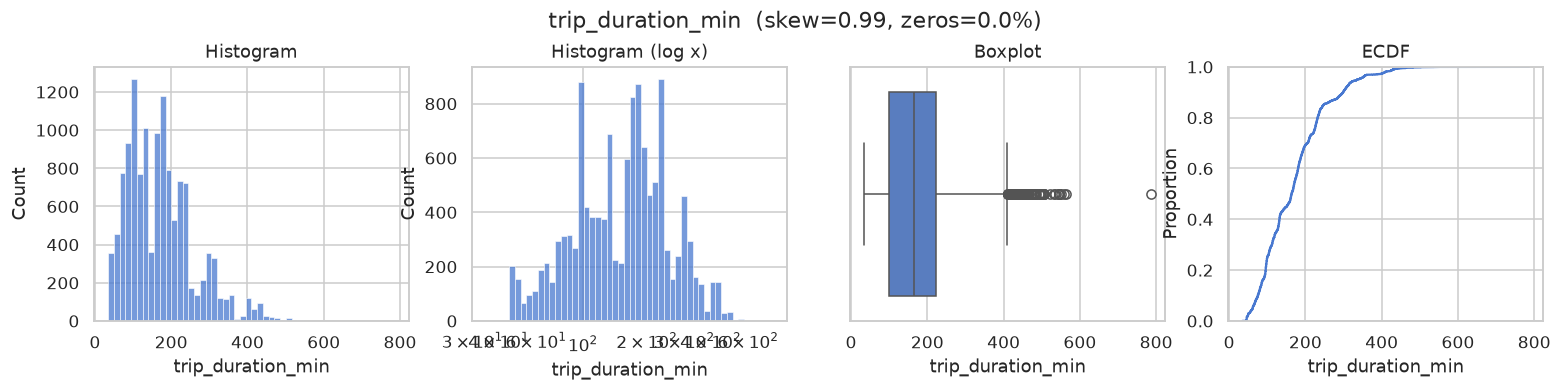

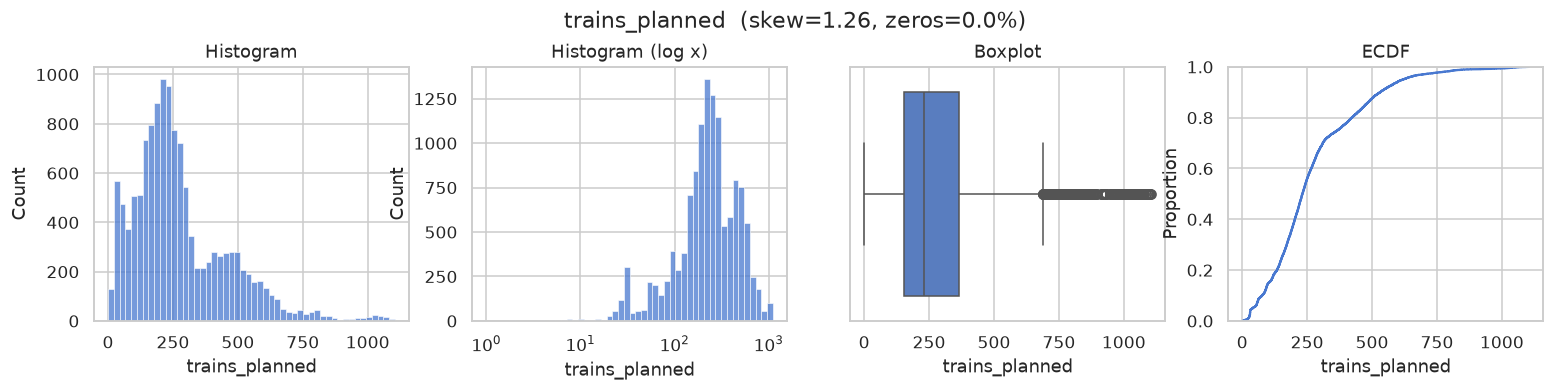

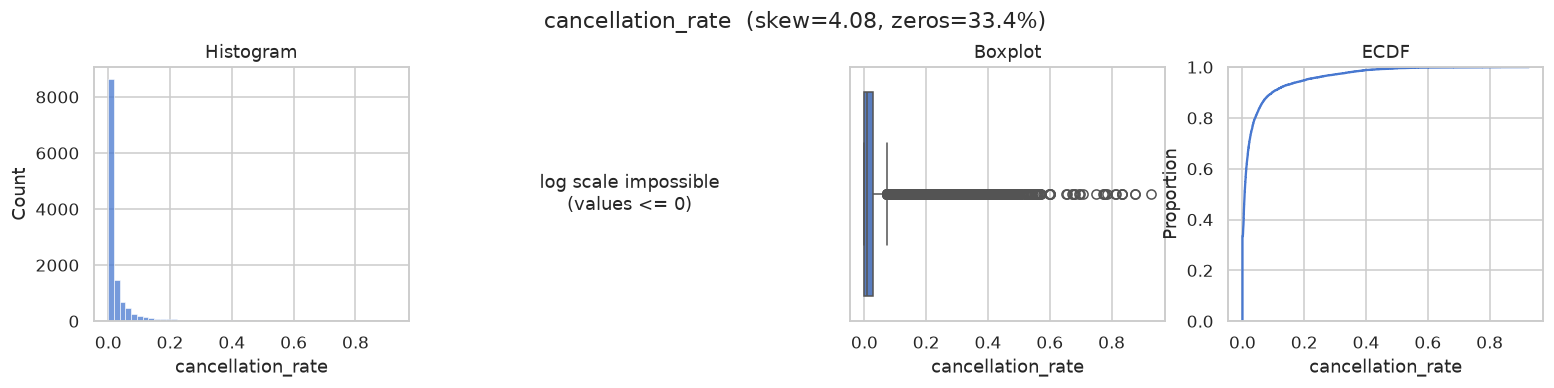

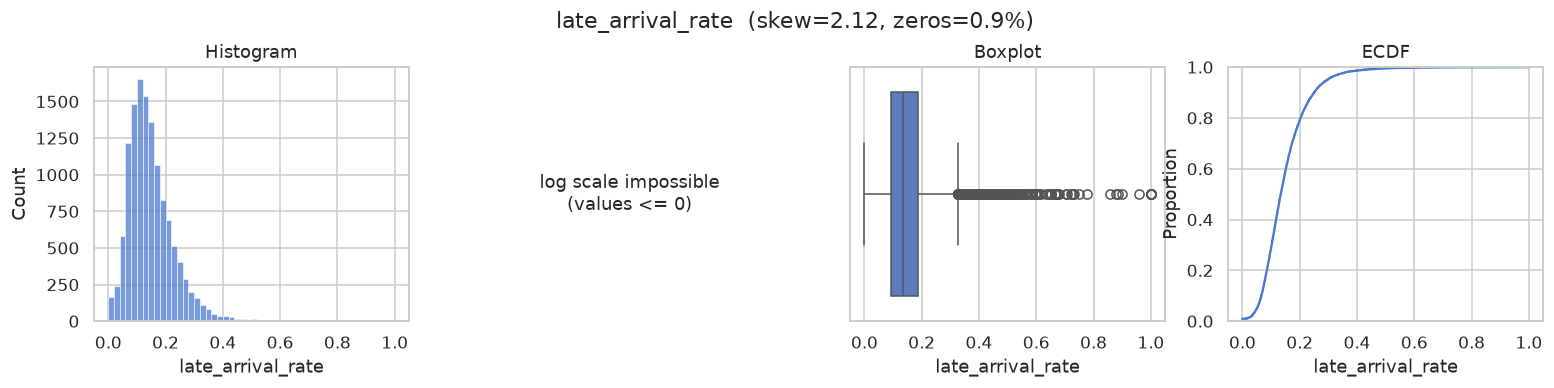

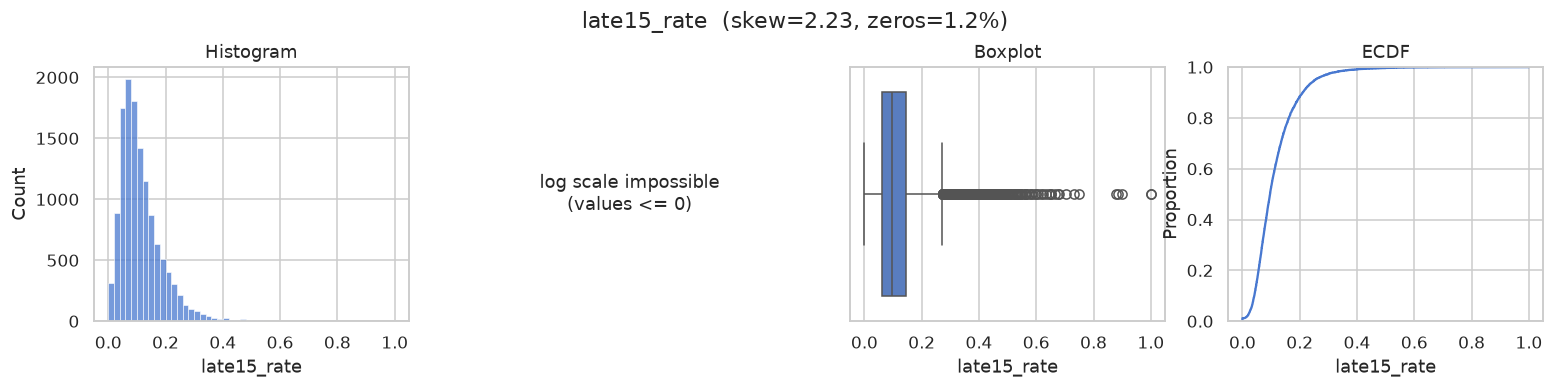

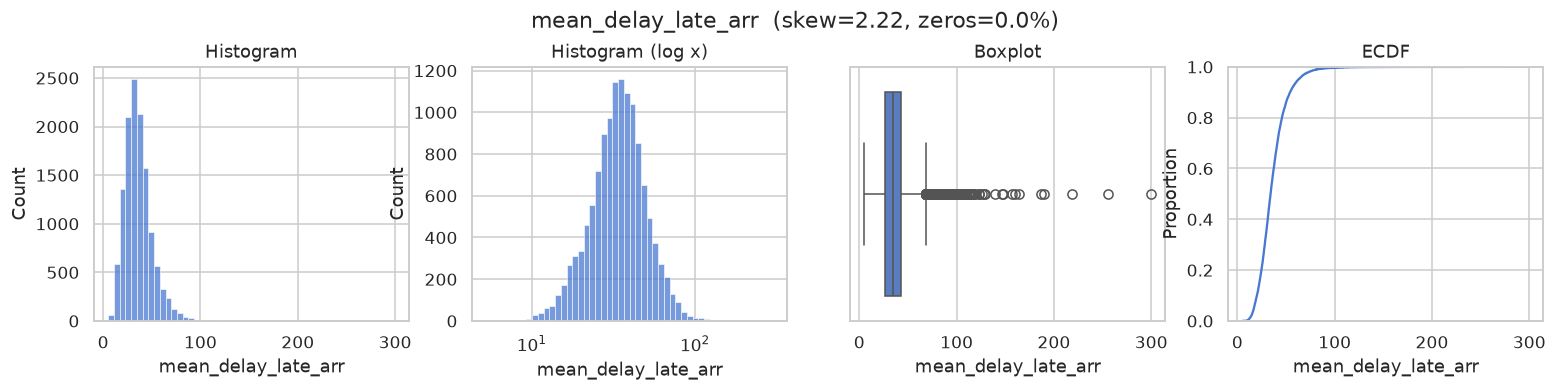

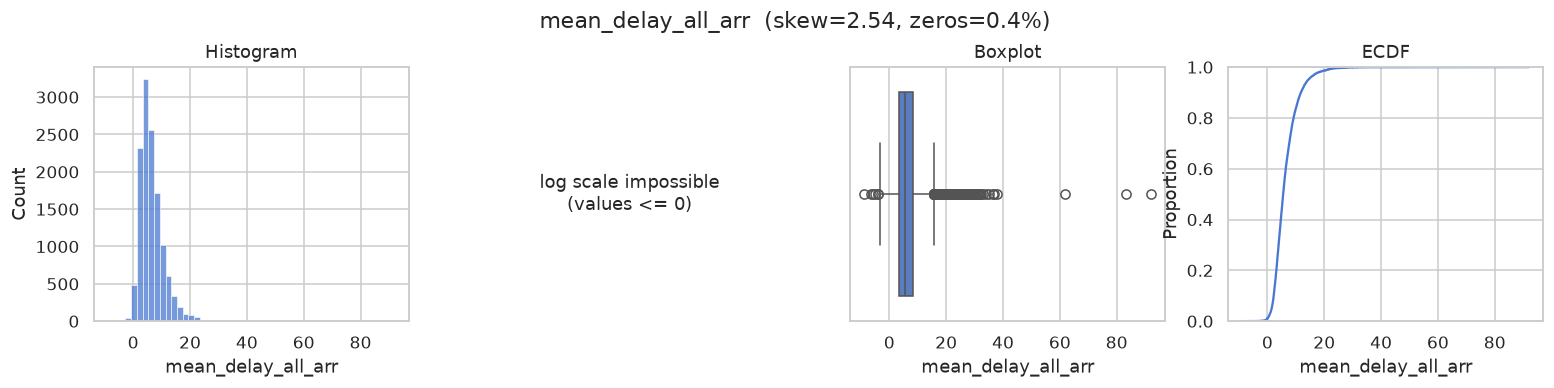

In [16]:
def plot_distribution(data: pd.DataFrame, col: str) -> None:
    """Histogram (linear and log), boxplot and ECDF of one variable."""
    x = data[col].dropna()
    fig, axes = plt.subplots(1, 4, figsize=(17, 3))
    sns.histplot(x, bins=50, ax=axes[0])
    axes[0].set_title("Histogram")
    if (x > 0).all():
        sns.histplot(x, bins=50, log_scale=True, ax=axes[1])
        axes[1].set_title("Histogram (log x)")
    else:
        axes[1].text(
            0.5, 0.5, "log scale impossible\n(values <= 0)", ha="center", va="center"
        )
        axes[1].set_axis_off()
    sns.boxplot(x=x, ax=axes[2])
    axes[2].set_title("Boxplot")
    sns.ecdfplot(x, ax=axes[3])
    axes[3].set_title("ECDF")
    fig.suptitle(f"{col}  (skew={x.skew():.2f}, zeros={(x == 0).mean():.1%})", y=1.05)
    plt.show()


for col in [
    "trip_duration_min",
    "trains_planned",
    "cancellation_rate",
    "late_arrival_rate",
    "late15_rate",
    "mean_delay_late_arr",
    "mean_delay_all_arr",
]:
    plot_distribution(clean, col)

📌 **Ce que montre l'univarié, après nettoyage**

- **Le nettoyage a fait son travail** : la durée minimale passe de 0 à 35 min, le retard moyen
  minimal de −472 à −8,8 min, et le « retard moyen des trains en retard » ne descend plus
  sous **5,3 min**. Ce dernier point est une belle vérification : 5 min est exactement le plus
  petit seuil composite de la SNCF, donc aucun train « en retard » ne peut l'être de moins.
- **Durée** : médiane 2 h 44 (164 min), la moitié des liaisons entre 1 h 40 et 3 h 45 ; maximum
  13 h (international).
- **Volume** : médiane 232 trains prévus par mois, avec un facteur supérieur à 7 entre les petites
  et les grandes liaisons. → **les comptages bruts mesurent la taille** : on ne compare jamais des
  comptages entre liaisons, toujours des taux.
- **Annulations** : médiane **0,7 %**, mais moyenne **3,7 %**, et 33 % des mois sans aucune
  annulation. Distribution « gonflée en zéro » avec une longue traîne (les mois de crise). La
  moyenne y est trompeuse : on raisonne en médiane et en quantiles, et on transforme (Yeo-Johnson)
  avant le clustering.
- **Retards de plus de 15 min** : médiane **9,6 %**, la moitié des mois entre 6,3 % et 14,7 %.
- **Retards de plus de 60 min** : 14 % de mois à zéro, médiane 3 trains : à l'échelle d'un mois,
  c'est un **petit comptage, donc bruité**. Agrégé sur huit ans par liaison, il devient exploitable.
- **Causes** (graphique suivant) : quatre familles autour de 20 % chacune (externes,
  infrastructure, gestion du trafic, matériel roulant) ; gestion en gare et prise en charge des
  voyageurs autour de 5 à 6 %, avec 26 à 30 % de zéros.

**Questions à se poser devant chaque graphique**
- *Forme* : une seule bosse ou plusieurs ? Plusieurs bosses (multimodalité) annoncent souvent
  des sous-populations (ex. liaisons courtes / longues) : c'est **précisément** ce qu'un
  clustering pourrait retrouver… ou ce qui pourrait le piéger.
- *Échelle* : si l'histogramme en log est plus lisible, la variable est multiplicative ; une
  transformation log (ou Yeo-Johnson) avant le clustering évitera que les extrêmes dominent.
- *ECDF* : lit directement « X % des mois-liaisons ont moins de Y % de trains en retard ».
- *Extrêmes* : sont-ils concentrés sur quelques mois ? (→ section 9, mois exceptionnels).

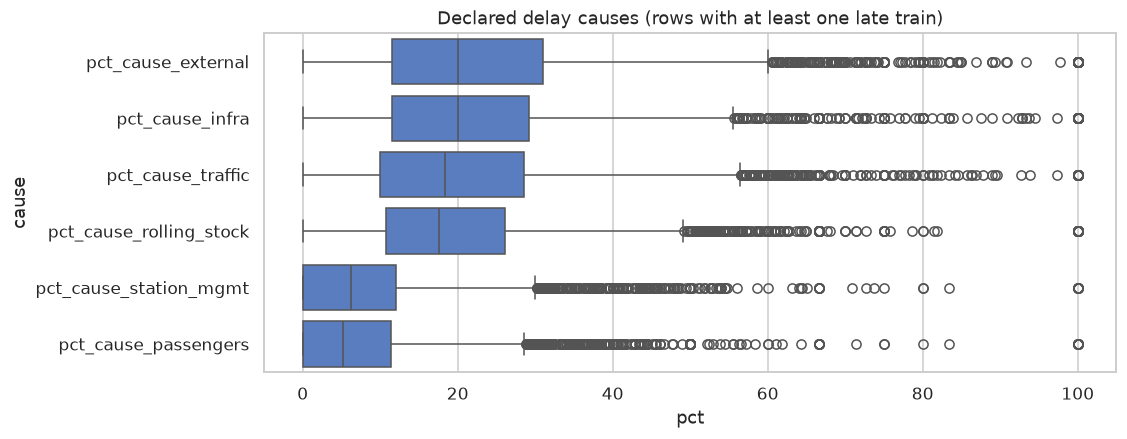

In [17]:
# Cause shares: compositional data (sum = 100) -> look at them together
fig, ax = plt.subplots(figsize=(10, 4))
clean[PCT_COLS].melt(var_name="cause", value_name="pct").pipe(
    lambda d: sns.boxplot(data=d, y="cause", x="pct", ax=ax)
)
ax.set_title("Declared delay causes (rows with at least one late train)")
plt.show()

## I.8 Univarié qualitatif

Pour une variable nominale : effectifs, modalités rares, **cohérence des libellés** (casse,
espaces, accents, abréviations). Deux libellés pour une même gare créent deux « liaisons »
distinctes et faussent tous les regroupements.

service
NATIONAL         11293
INTERNATIONAL     1541
Name: count, dtype: int64 



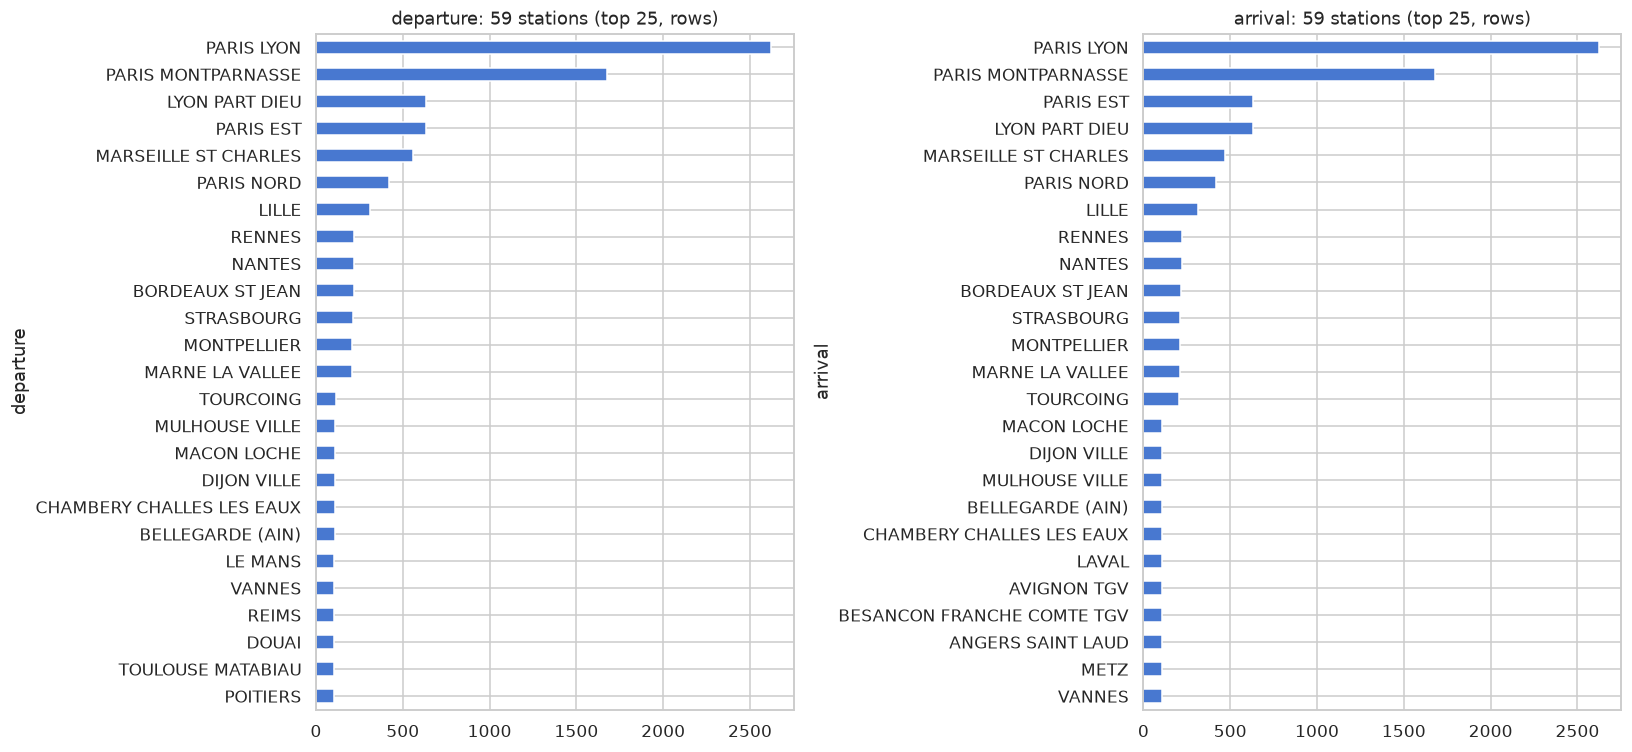

In [18]:
print(clean["service"].value_counts(), "\n")
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, col in zip(axes, ["departure", "arrival"], strict=True):
    clean[col].value_counts().head(25).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{col}: {clean[col].nunique()} stations (top 25, rows)")
plt.tight_layout()
plt.show()

In [19]:
# Near-duplicate station labels: same name once accents,
# punctuation and spaces are removed
import unicodedata


def normalise(label: str) -> str:
    """Upper-case ASCII key without punctuation or spaces."""
    ascii_label = (
        unicodedata.normalize("NFKD", label).encode("ascii", "ignore").decode()
    )
    return "".join(ch for ch in ascii_label.upper() if ch.isalnum())


stations = pd.Series(pd.unique(clean[["departure", "arrival"]].values.ravel()))
groups = stations.groupby(stations.map(normalise)).agg(list)
print("Labels that collapse to the same key:")
print(groups[groups.map(len) > 1])

Labels that collapse to the same key:
Series([], dtype: object)


In [20]:
# Routes: how many, observed in both directions?
pairs = set(zip(clean["departure"], clean["arrival"], strict=True))
both = sum((a, d) in pairs for d, a in pairs)
print(f"{len(pairs)} oriented routes; {both} have their reverse direction")
clean.groupby("route").size().describe()

130 oriented routes; 130 have their reverse direction


count   130.0000
mean     98.7231
std      22.4016
min      12.0000
25%     104.0000
50%     105.0000
75%     105.0000
max     108.0000
dtype: float64

📌 **À retenir** — 130 liaisons orientées, **toutes** présentes dans les deux sens ; 12 % des
lignes en service international (1 541 sur 12 834) ; aucun libellé de gare en double après
normalisation. Pas d'action nécessaire, mais le contrôle doit rester dans le pipeline : un nouvel
export peut changer.

## I.9 Univarié temporel

Trois questions :
1. **Panel équilibré ?** Toutes les liaisons sont-elles observées tous les mois ? Sinon, une
   « évolution » du réseau peut venir d'un changement de composition (Simpson, session 2).
2. **Mois exceptionnels** : on part d'une **liste d'événements documentés** (grèves, confinements)
   écrite **avant** de regarder les résultats, puis on **confirme** chaque mois avec les données
   (z-score robuste vs le même mois des autres années). La détection automatique sert seulement à
   repérer des **candidats** à documenter, jamais à exclure d'office.
3. **Saisonnalité** : heatmap année × mois du taux de retard réseau.

**Pourquoi cette approche plutôt que la détection automatique** (v2) : exclure un mois parce
qu'il est *mauvais* revient à retirer de l'analyse… les mauvais résultats, alors qu'ils sont
précisément ce qu'on mesure. Une grève ou un confinement est un **choc extérieur** à la qualité
d'exploitation d'une liaison : on peut le retirer en le justifiant. Un mois de canicule ou un mois
simplement mauvais fait partie du profil de ponctualité : on le garde.

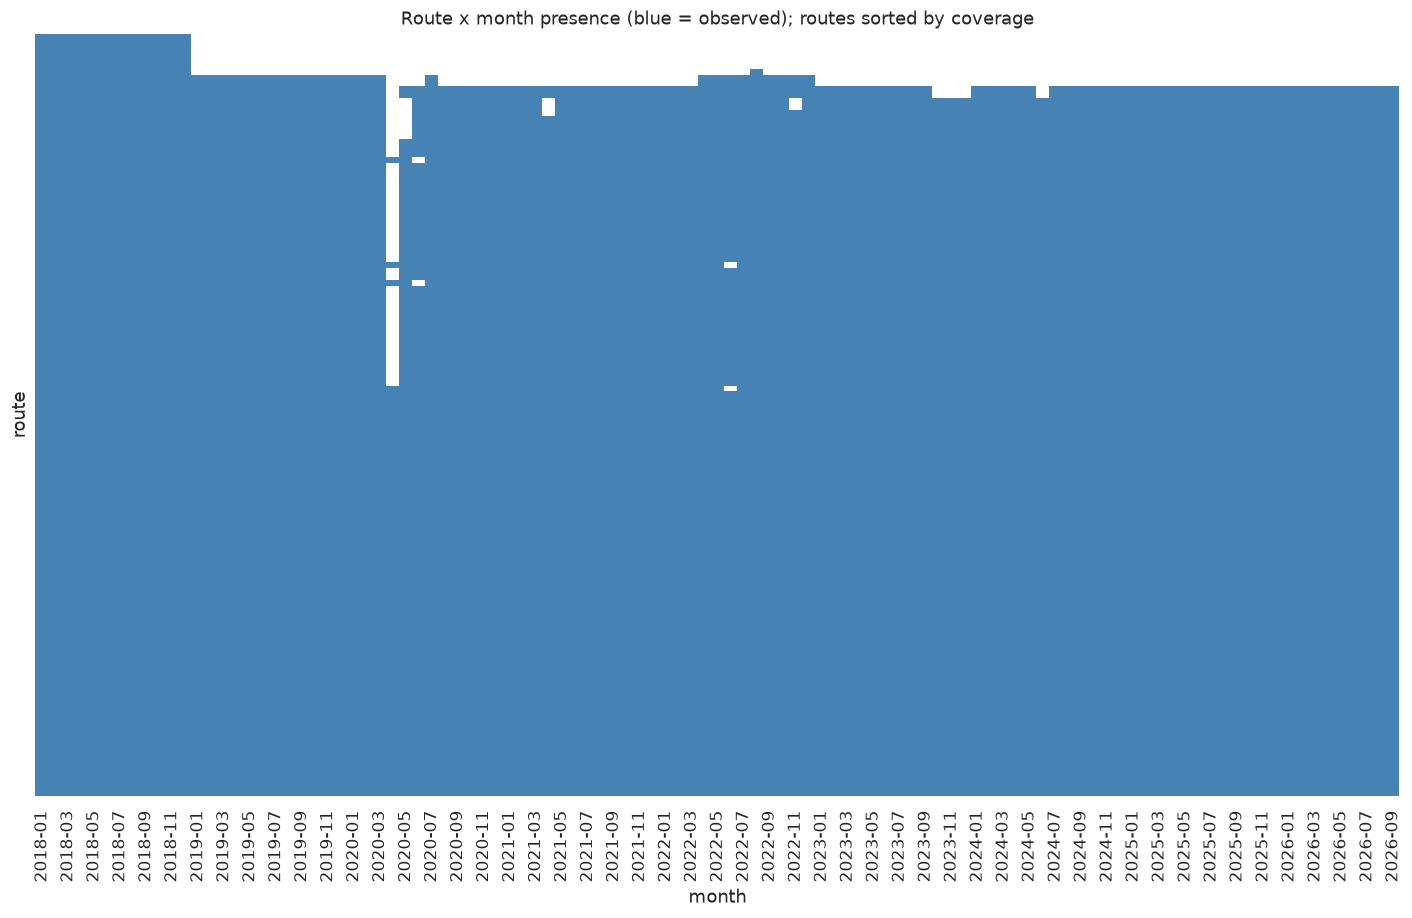

count   130.0000
mean     98.4000
std      22.2901
min      12.0000
25%     104.0000
50%     105.0000
75%     105.0000
max     105.0000
dtype: float64


In [21]:
presence = (
    clean.assign(month=clean["date"].astype(str))
    .pivot_table(
        index="route", columns="month", values="trains_planned", aggfunc="size"
    )
    .notna()
)
fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(
    presence.loc[presence.sum(axis=1).sort_values().index],
    cbar=False,
    cmap=["white", "steelblue"],
    ax=ax,
    yticklabels=False,
)
ax.set_title("Route x month presence (blue = observed); routes sorted by coverage")
plt.show()
print(presence.sum(axis=1).describe())

📌 **À retenir** — le panel est presque équilibré (médiane 105 mois sur 105), avec trois écarts :

- quelques liaisons observées **seulement en 2018** (12 mois : les liaisons de Paris Vaugirard,
  Tourcoing → Marseille). Elles sont écartées par le seuil d'éligibilité de 24 mois ;
- **avril–mai 2020** : de nombreuses liaisons absentes (plan de transport du confinement) ;
- **janvier–mars 2025** : de nombreuses liaisons absentes **sans événement connu**. C'est un
  **trou de publication**. Toute évolution calculée sur le réseau début 2025 compare des
  ensembles de liaisons différents (le piège de Simpson, session 2).

In [22]:
# ── Documented external shocks (hypotheses to CONFIRM with the data) ──────────
# type: strike / covid (network-wide supply shocks, unrelated to a route's own quality).
# Weather (snow, heat waves) is NOT listed: routes are unequally exposed to it, so it is
# part of their punctuality profile. Sources to add in the datasheet.
KNOWN_EVENTS = pd.DataFrame(
    [
        ("2018-04", "Grève perlée SNCF (réforme ferroviaire)", "strike", "high"),
        ("2018-05", "Grève perlée SNCF (réforme ferroviaire)", "strike", "high"),
        ("2018-06", "Grève perlée SNCF (réforme ferroviaire)", "strike", "high"),
        ("2019-12", "Grève contre la réforme des retraites", "strike", "high"),
        ("2020-01", "Grève contre la réforme des retraites", "strike", "high"),
        ("2020-02", "Fin de la grève des retraites (liste v1)", "strike", "low"),
        ("2020-03", "1er confinement COVID-19 (à partir du 17/03)", "covid", "high"),
        ("2020-04", "1er confinement COVID-19", "covid", "high"),
        ("2020-05", "1er confinement COVID-19 (fin le 11/05)", "covid", "high"),
        (
            "2020-06",
            "Plan de transport réduit après confinement (liste v1)",
            "covid",
            "medium",
        ),
        ("2020-11", "2e confinement COVID-19", "covid", "high"),
        ("2020-12", "2e confinement (fin le 15/12)", "covid", "medium"),
        ("2021-04", "3e confinement COVID-19", "covid", "high"),
        ("2021-05", "Restrictions de déplacement (fin le 03/05)", "covid", "medium"),
        ("2022-12", "Grève des contrôleurs (week-end de Noël)", "strike", "high"),
        ("2023-01", "Grèves contre la réforme des retraites", "strike", "high"),
        ("2023-02", "Grèves contre la réforme des retraites", "strike", "high"),
        ("2023-03", "Grèves contre la réforme des retraites", "strike", "high"),
        ("2024-02", "Grève des contrôleurs (vacances d'hiver)", "strike", "high"),
        (
            "2026-06",
            "Grève nationale du 10 juin 2026 (≈ 2 TGV sur 3)",
            "strike",
            "medium",
        ),
    ],
    columns=["month", "event", "type", "confidence"],
)
KNOWN_MONTHS = KNOWN_EVENTS["month"].tolist()


def robust_z(x: pd.Series) -> pd.Series:
    """Robust z-score: (x - median) / (1.4826 * MAD)."""
    mad = 1.4826 * (x - x.median()).abs().median()
    return (x - x.median()) / mad if mad > 0 else x * 0.0


def network_month_scores(data: pd.DataFrame) -> pd.DataFrame:
    """Network rates per month and their robust z-score vs the same calendar month."""
    ok = data.dropna(subset=["trains_cancelled", "late_15min"])
    net = ok.groupby("date")[
        ["trains_planned", "trains_cancelled", "late_15min", "trains_run"]
    ].sum()
    rates = pd.DataFrame(
        {
            "cancellation_rate": net["trains_cancelled"] / net["trains_planned"],
            "late15_rate": net["late_15min"]
            / net["trains_run"].where(net["trains_run"] > 0),
        }
    )
    residual = rates - rates.groupby(rates.index.month).transform("median")
    z = residual.apply(robust_z).add_prefix("z_")
    out = rates.join(z)
    out["max_z"] = z.max(axis=1)
    out.index = out.index.astype(str)
    return out


def detected_months(scores: pd.DataFrame, z_threshold: float = 3.5) -> list[str]:
    """Months where the network is abnormal (data-driven, for comparison only)."""
    return sorted(scores.index[scores["max_z"] > z_threshold])


scores = network_month_scores(clean)
confirmation = KNOWN_EVENTS.set_index("month").join(
    scores[
        [
            "cancellation_rate",
            "late15_rate",
            "z_cancellation_rate",
            "z_late15_rate",
            "max_z",
        ]
    ]
)
confirmation["confirmed (z > 3.5)"] = confirmation["max_z"] > 3.5
display(confirmation.round(3))

DETECTED_MONTHS = detected_months(scores)
candidates = scores.loc[
    [m for m in DETECTED_MONTHS if m not in KNOWN_MONTHS],
    ["cancellation_rate", "late15_rate", "max_z"],
]
print("Abnormal months NOT in the documented list (to investigate, NOT excluded):")
candidates.round(3)

,event,type,confidence,cancellation_rate,late15_rate,z_cancellation_rate,z_late15_rate,max_z,confirmed (z > 3.5)
month,,,,,,,,,
2018-04,Grève perlée SNCF (réforme ferroviaire),strike,high,0.3270,0.1080,41.7660,0.3150,41.7660,True
2018-05,Grève perlée SNCF (réforme ferroviaire),strike,high,0.2450,0.1170,30.6390,1.8850,30.6390,True
2018-06,Grève perlée SNCF (réforme ferroviaire),strike,high,0.1510,0.1390,19.0880,0.4330,19.0880,True
2019-12,Grève contre la réforme des retraites,strike,high,0.1600,0.1230,19.2400,1.4670,19.2400,True
2020-01,Grève contre la réforme des retraites,strike,high,0.0560,0.0900,5.3810,-0.5980,5.3810,True
2020-02,Fin de la grève des retraites (liste v1),strike,low,0.0110,0.0800,-0.1230,-0.1280,-0.1230,False
2020-03,1er confinement COVID-19 (à partir du 17/03),covid,high,0.0960,0.1100,11.2230,1.4600,11.2230,True
2020-04,1er confinement COVID-19,covid,high,0.4670,0.1590,60.1600,3.2880,60.1600,True
2020-05,1er confinement COVID-19 (fin le 11/05),covid,high,0.1660,0.0580,20.2980,-1.5940,20.2980,True


Abnormal months NOT in the documented list (to investigate, NOT excluded):


,cancellation_rate,late15_rate,max_z
date,,,
2018-02,0.0230,0.1570,4.3350
2018-07,0.0540,0.1990,4.5350
2019-06,0.0330,0.1160,3.6500
2019-07,0.0470,0.1170,3.6100
2026-01,0.0210,0.1740,4.3390
2026-07,0.0220,0.1910,3.5320


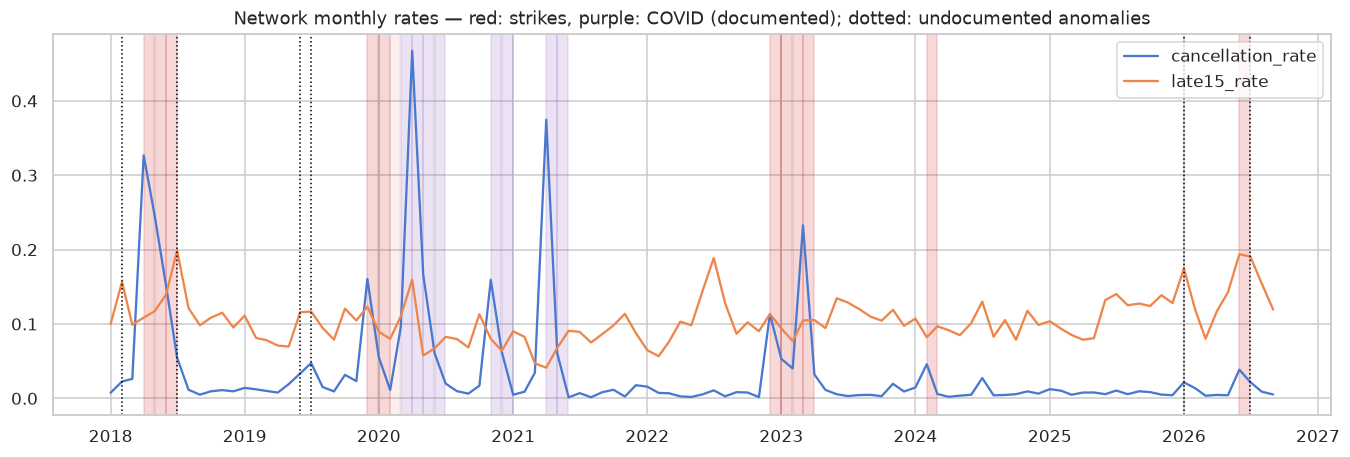

In [23]:
net = scores[["cancellation_rate", "late15_rate"]].copy()
net.index = pd.PeriodIndex(net.index, freq="M")
fig, ax = plt.subplots(figsize=(15, 4.5))
ts = net.index.to_timestamp()
ax.plot(ts, net["cancellation_rate"], label="cancellation_rate")
ax.plot(ts, net["late15_rate"], label="late15_rate")
colors = {"strike": "tab:red", "covid": "tab:purple"}
for _, ev in KNOWN_EVENTS.iterrows():
    start = pd.Period(ev["month"], "M").to_timestamp()
    ax.axvspan(
        start,
        start + pd.offsets.MonthEnd(1),
        color=colors[ev["type"]],
        alpha=0.18 if ev["confidence"] != "low" else 0.07,
    )
for m in candidates.index:
    ax.axvline(pd.Period(m, "M").to_timestamp(), color="black", ls=":", lw=1)
ax.legend()
ax.set_title(
    "Network monthly rates — red: strikes, purple: COVID (documented);"
    " dotted: undocumented anomalies"
)
plt.show()

📌 **Les événements documentés sont-ils confirmés par les données ?** Oui, **19 sur 20**.

- **Les chocs les plus nets** (z-score d'annulation) : avril 2020 (47 % de trains annulés, z = 60),
  avril 2021 (37,5 %, 3e confinement, z = 48), avril 2018 (33 %, grève perlée, z = 42), mars 2023
  (23 %, retraites, z = 29).
- **Les plus faibles mais confirmés** : février 2023 (z = 3,7), février 2024 (z = 4,4) et juin 2026
  (z = 4,3). La grève du 10 juin 2026 ne dure qu'un jour, mais juin 2026 est aussi anormal côté
  retards (19,4 % de trains à plus de 15 min).
- **Février 2020 n'est pas confirmé** (z = −0,1) : la grève des retraites s'essouffle mi-janvier.
  → **à retirer de la liste.** Il ne restera alors que 19 mois exclus.

**Mois anormaux absents de la liste** : février 2018, juillet 2018, juin et juillet 2019,
janvier 2026, juillet 2026. Ils ont tous un point commun : ce sont des **pics de retard sans pic
d'annulation** (jusqu'à 19,9 % de trains à plus de 15 min en juillet 2018). Neige, canicules,
difficultés d'exploitation : ces mois font partie de ce qu'on mesure. **On les garde.**

C'est toute la différence avec l'approche précédente. La détection automatique excluait 24 mois,
dont ces mois simplement mauvais, et retirait donc de l'analyse… les mauvais résultats.

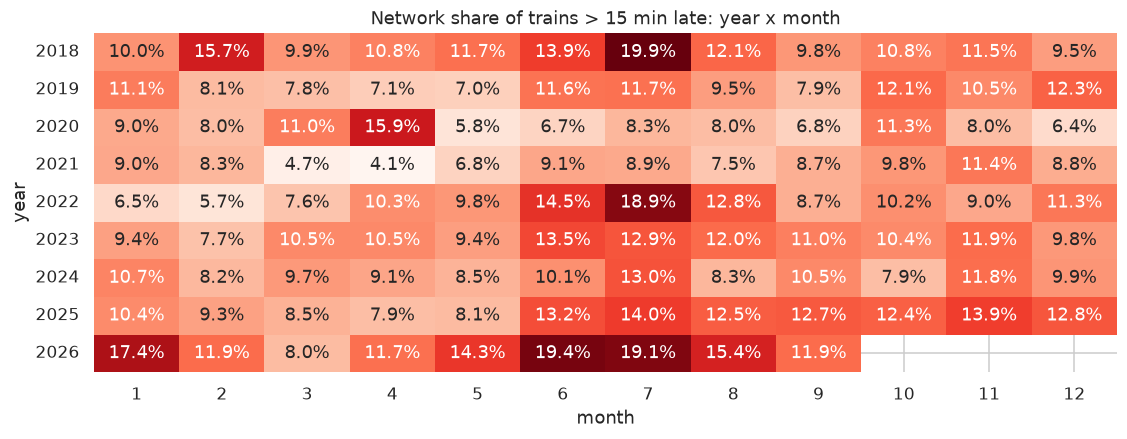

In [24]:
heat = (
    net["late15_rate"]
    .to_frame()
    .assign(year=lambda d: d.index.year, month=lambda d: d.index.month)
    .pivot(index="year", columns="month", values="late15_rate")
)
plt.figure(figsize=(12, 4))
sns.heatmap(heat, annot=True, fmt=".1%", cmap="Reds", cbar=False)
plt.title("Network share of trains > 15 min late: year x month")
plt.show()

📌 **Ce que montre la heatmap**

- **Une saisonnalité nette** : chaque année, juin, juillet et août sont les mois les plus mauvais
  (souvent 13 à 20 % de trains à plus de 15 min). Chaleur, travaux d'été, affluence : à expliquer
  dans l'article, pas à exclure.
- **2026 est la pire année de la série** : janvier 17,4 %, juin 19,4 %, juillet 19,1 %. C'est un
  résultat pour la Q1 (dégradation récente).
- **Les printemps 2020 et 2021 paraissent excellents** (4 à 6 %) : ce n'est pas une meilleure
  exploitation, c'est **moins de trains**, donc moins de congestion. Exemple typique de facteur de
  confusion : le volume de trafic.

## I.10 Synthèse pour le clustering

| Constat | Conséquence pour la Q3 |
|---|---|
| Les comptages mesurent la taille des liaisons | Ne jamais clusteriser des comptages bruts : utiliser des **taux** |
| Valeurs impossibles dans des colonnes bien typées | Décisions D1 à D10, **invalidation par champ**, ratios sur paires valides |
| `late_30min` par tranches sur une partie de 2025 | À reconstruire dans le pipeline ; effet modéré sur les profils, fort sur les tendances |
| Doublons *(mois, liaison)* à l'été 2025 | Vérifier s'il s'agit de trains distincts avant de sommer |
| Annulations : médiane 0,7 %, 33 % de zéros, longue traîne | Transformation Yeo-Johnson ; médianes plutôt que moyennes |
| Causes = composition (somme 100) | Ne pas les mettre dans les distances |
| 19 événements documentés confirmés, février 2020 non | Exclure ces 19 mois ; mesurer l'impact (II.10) |
| Saisonnalité estivale, dégradation de 2026, mois de canicule | Les garder : ils font partie des profils |
| Trou de publication début 2025 | À signaler (datasheet, Q1) |
| Liaisons à couverture partielle | Seuil d'éligibilité de 24 mois |

# Partie II — Profils de ponctualité des liaisons (K-means)

**Question** : peut-on regrouper les liaisons par « profil de ponctualité » (bonne régularité,
retards chroniques mineurs, retards rares mais sévères…) à l'aide d'un clustering ?

**Type de question** : exploratoire. On peut conclure « les liaisons se répartissent en *k*
groupes de comportement distinct » **si** la structure résiste aux tests de robustesse ; on ne peut
pas conclure *pourquoi* une liaison est dans un groupe.

### Ce que la version précédente nous a appris, et ce qui a changé

| Avant | Ce qu'on a compris | Maintenant |
|---|---|---|
| 2 groupes bien séparés (silhouette 0,39) | Ils opposaient en fait liaisons **courtes** (≈ 100 min) et **longues** (≈ 210 min) | Option d'**ajustement à la durée** (II.3) |
| `late15_rate`, `volatility`, `chronicity` dans les variables | Corrélées entre 0,88 et 0,98 : **une seule information comptée trois fois** | Jeu `v3` dédoublonné |
| La gravité des retards ne distinguait pas les groupes | Elle était écrasée par le triple poids de la fréquence | Ajout des retards **> 60 min** (`extreme_share`) |
| Mois exceptionnels détectés automatiquement (24 mois) | On excluait aussi des mois simplement mauvais | Liste d'**événements documentés**, confirmée par les données |
| ACP sans cercle des corrélations | Impossible de savoir quelle variable tire dans quel sens | Toute ACP a son cercle |

### Paramètres (futurs widgets Streamlit)
Toute la suite dépend de ces six paramètres : ce sont exactement les contrôles que l'app Streamlit expose.

In [25]:
FEATURE_SET = "v3"  # "v3" (recommended), "fixed" (v2), "composite" (v1)  -> st.radio
ADJUST_DURATION = (
    True  # remove the mechanical effect of trip duration       -> st.toggle
)
EXCLUSION = "known"  # "none", "known" (documented events), "data"         -> st.radio
SCALER = "power"  # "power" (Yeo-Johnson) or "standard"                 -> st.selectbox
K = None  # None = chosen by silhouette, or an int              -> st.select_slider
MIN_MONTHS = 24  # eligibility threshold                               -> st.slider

## II.1 Données de départ : la table nettoyée de la partie I, puis l'exclusion choisie

In [26]:
data = clean.copy()
EXCLUDED = {"none": [], "known": KNOWN_MONTHS, "data": DETECTED_MONTHS}[EXCLUSION]
data_normal = data[~data["date"].astype(str).isin(EXCLUDED)].copy()
print(
    f"Exclusion '{EXCLUSION}': {len(EXCLUDED)} months removed"
    f" -> {len(data_normal)} rows"
)

Exclusion 'known': 20 months removed -> 10437 rows


In [27]:
# ── Route-level features v3 (formulas in section II.2) ─────────────────────────
def ratio_of_sums(
    data: pd.DataFrame, num: str, den: str, by: str = "route"
) -> pd.Series:
    """Sum(num) / Sum(den) per group, on rows where BOTH fields are valid."""
    ok = data[num].notna() & data[den].notna()
    g = data[ok].groupby(by)
    return g[num].sum() / g[den].sum().where(lambda s: s > 0)


def build_route_features(data: pd.DataFrame) -> pd.DataFrame:
    """One row per route: fixed-threshold, tail, temporal and composite features."""
    g = data.groupby("route")
    out = pd.DataFrame(index=pd.Index(sorted(data["route"].unique()), name="route"))
    out["n_months"] = g["date"].nunique()
    out["trains_run_total"] = g["trains_run"].sum()
    out["trip_duration_min"] = g["trip_duration_min"].median()
    # Frequency (fixed thresholds), unconditional
    out["cancellation_rate"] = ratio_of_sums(data, "trains_cancelled", "trains_planned")
    out["late15_rate"] = ratio_of_sums(data, "late_15min", "trains_run")
    out["late30_rate"] = ratio_of_sums(data, "late_30min", "trains_run")
    out["late60_rate"] = ratio_of_sums(data, "late_60min", "trains_run")
    # Severity / tail, conditional on being > 15 min late
    out["severe_share"] = ratio_of_sums(data, "late_30min", "late_15min").fillna(0)
    out["extreme_share"] = ratio_of_sums(data, "late_60min", "late_15min").fillna(0)
    out["tail_ratio"] = ratio_of_sums(data, "late_60min", "late_30min").fillna(0)
    # Temporal behaviour of the monthly > 15 min rate
    run = data[(data["trains_run"] > 0) & data["late_15min"].notna()].assign(
        r15=lambda d: d["late_15min"] / d["trains_run"]
    )
    net = run.groupby("date")[["late_15min", "trains_run"]].sum()
    run = run.join((net["late_15min"] / net["trains_run"]).rename("net_r15"), on="date")
    r15 = run.groupby("route")["r15"]
    out["volatility"] = r15.std().fillna(0)
    out["volatility_cv"] = (r15.std() / r15.mean()).fillna(0)
    out["chronicity"] = (run["r15"] > run["net_r15"]).groupby(run["route"]).mean()
    # Composite threshold (v1, kept for comparison)
    out["late_arrival_rate"] = ratio_of_sums(data, "late_arrival", "trains_run")
    ok = data["mean_delay_late_arr"].notna() & data["late_arrival"].notna()
    w = (
        (data.loc[ok, "mean_delay_late_arr"] * data.loc[ok, "late_arrival"])
        .groupby(data.loc[ok, "route"])
        .sum()
    )
    out["mean_delay_when_late"] = w / data[ok].groupby("route")["late_arrival"].sum()
    out["severe_ratio"] = ratio_of_sums(data, "late_30min", "late_arrival")
    out["irregularity"] = (
        run.assign(rc=lambda d: d["late_arrival"] / d["trains_run"])
        .groupby("route")["rc"]
        .std()
        .fillna(0)
    )
    return out


def adjust_for_duration(
    features: pd.DataFrame, cols: list[str]
) -> tuple[pd.DataFrame, pd.Series]:
    """Remove the linear effect of log(duration): value expected at the mean duration.

    f_adj = f - b * (ln D - mean(ln D)), b estimated by OLS across routes.
    Returns the adjusted features and the slopes b.
    """
    out = features.copy()
    log_d = np.log(features["trip_duration_min"])
    slopes = {}
    for col in cols:
        b, _ = np.polyfit(log_d, features[col], deg=1)
        out[col] = features[col] - b * (log_d - log_d.mean())
        slopes[col] = b
    return out, pd.Series(slopes, name="slope_per_log_minute")


FEATURE_SETS = {
    "v3": [
        "cancellation_rate",
        "late15_rate",
        "severe_share",
        "extreme_share",
        "volatility_cv",
    ],
    "fixed": [
        "cancellation_rate",
        "late15_rate",
        "severe_share",
        "volatility",
        "chronicity",
    ],
    "composite": [
        "cancellation_rate",
        "late_arrival_rate",
        "mean_delay_when_late",
        "severe_ratio",
        "irregularity",
    ],
}


routes = build_route_features(data_normal)
eligible = routes[routes["n_months"] >= MIN_MONTHS].copy()
print(f"{len(eligible)} eligible routes / {len(routes)} (>= {MIN_MONTHS} months)")

123 eligible routes / 130 (>= 24 months)


In [28]:
# ── Helpers: PCA with correlation circle, correlation ratio ────────────────────
from sklearn.decomposition import PCA


def pca_with_circle(
    x_mat: np.ndarray, names: list[str], labels=None, title: str = ""
) -> pd.DataFrame:
    """Scatter of individuals on PC1/PC2 + correlation circle of the variables.

    The arrows are the correlations between each (scaled) variable and each
    principal component. Returns that correlation table.
    """
    pca = PCA(n_components=2, random_state=SEED).fit(x_mat)
    scores = pca.transform(x_mat)
    ev = pca.explained_variance_ratio_
    corr = np.array(
        [
            [np.corrcoef(x_mat[:, j], scores[:, c])[0, 1] for c in range(2)]
            for j in range(x_mat.shape[1])
        ]
    )
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6.5))
    sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=labels, s=50, ax=a1)
    a1.axhline(0, color="grey", lw=0.5)
    a1.axvline(0, color="grey", lw=0.5)
    a1.set(
        xlabel=f"PC1 ({ev[0]:.0%})",
        ylabel=f"PC2 ({ev[1]:.0%})",
        title="Individus (liaisons)",
    )
    a2.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
    a2.axhline(0, color="grey", lw=0.5)
    a2.axvline(0, color="grey", lw=0.5)
    for j, name in enumerate(names):
        a2.arrow(
            0,
            0,
            corr[j, 0],
            corr[j, 1],
            head_width=0.03,
            length_includes_head=True,
            color="tab:blue",
        )
        a2.text(
            corr[j, 0] * 1.1,
            corr[j, 1] * 1.1,
            name,
            ha="center",
            va="center",
            fontsize=9,
        )
    a2.set(
        xlim=(-1.2, 1.2),
        ylim=(-1.2, 1.2),
        aspect="equal",
        title="Cercle des corrélations",
        xlabel=f"PC1 ({ev[0]:.0%})",
        ylabel=f"PC2 ({ev[1]:.0%})",
    )
    fig.suptitle(f"{title}  —  PC1 + PC2 = {ev.sum():.0%} de la variance", y=1.0)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(corr, index=names, columns=["corr_PC1", "corr_PC2"]).round(2)


def eta_squared(values, labels) -> float:
    """Share of the variance of `values` explained by the clusters
    (correlation ratio).
    """
    v = pd.Series(np.asarray(values, dtype=float))
    g = v.groupby(np.asarray(labels))
    return float(
        (g.size() * (g.mean() - v.mean()) ** 2).sum() / ((v - v.mean()) ** 2).sum()
    )

## II.2 Les indicateurs, en formules

**Notations.** Pour une liaison $r$ et un mois $m \in \mathcal{M}_r$ (mois observés, hors mois
exceptionnels) :

| Symbole | Signification | Colonne |
|---|---|---|
| $P_{r,m}$ | trains prévus | `trains_planned` |
| $A_{r,m}$ | trains annulés | `trains_cancelled` |
| $C_{r,m} = P_{r,m} - A_{r,m}$ | trains circulés | `trains_run` |
| $L^{15}_{r,m},\ L^{30}_{r,m},\ L^{60}_{r,m}$ | trains arrivés avec plus de 15, 30, 60 min de retard | `late_15min`… |
| $L^{\theta}_{r,m}$ | trains « en retard » au seuil composite $\theta(D_r)$ | `late_arrival` |
| $\bar{d}_{r,m}$ | retard moyen des trains en retard (seuil composite) | `mean_delay_late_arr` |

avec le seuil composite $\theta(D) = 5$ min si $D < 90$, $10$ min si $90 \le D \le 180$,
$15$ min sinon ($D$ = durée du trajet).

### Jeu « seuils fixes » (recommandé)

**1. Taux d'annulation** — les trains circulent-ils ?
$$\tau^{\text{ann}}_r = \frac{\sum_{m \in \mathcal{M}_r} A_{r,m}}{\sum_{m \in \mathcal{M}_r} P_{r,m}}$$

**2. Fréquence des retards > 15 min** — à quelle fréquence est-on nettement en retard ?
$$\tau^{15}_r = \frac{\sum_{m} L^{15}_{r,m}}{\sum_{m} C_{r,m}}$$

C'est un **ratio de sommes**. Il équivaut à une moyenne des taux mensuels pondérée par le
trafic, ce qui évite qu'un mois à 20 trains pèse autant qu'un mois à 900 :
$$\tau^{15}_r = \sum_{m} w_{r,m}\,\frac{L^{15}_{r,m}}{C_{r,m}}, \qquad w_{r,m} = \frac{C_{r,m}}{\sum_{m'} C_{r,m'}}$$

**3. Sévérité conditionnelle** — quand on est en retard de plus de 15 min, est-ce grave ?
$$s_r = \frac{\sum_{m} L^{30}_{r,m}}{\sum_{m} L^{15}_{r,m}} \;\approx\; \Pr(\text{retard} > 30 \mid \text{retard} > 15)$$

C'est l'axe qui sépare « retards fréquents mais courts » de « retards rares mais sévères ».

**4. Volatilité** — le comportement change-t-il d'un mois à l'autre ?
$$\sigma_r = \sqrt{\frac{1}{|\mathcal{M}^{+}_r| - 1}\sum_{m \in \mathcal{M}^{+}_r}\left(\tau^{15}_{r,m} - \overline{\tau^{15}_{r}}\right)^2},\qquad \tau^{15}_{r,m} = \frac{L^{15}_{r,m}}{C_{r,m}}$$
où $\mathcal{M}^{+}_r$ = mois avec au moins un train circulé. ⚠️ Pour une proportion, la variance
binomiale $p(1-p)/C$ augmente avec $p$ quand $p < 0{,}5$ : $\sigma_r$ est mécaniquement liée à
$\tau^{15}_r$ (à vérifier dans la matrice de corrélation).

**5. Chronicité** — la liaison fait-elle pire que le réseau *le même mois* ?
$$\chi_r = \frac{1}{|\mathcal{M}^{+}_r|}\sum_{m \in \mathcal{M}^{+}_r}\mathbb{1}\!\left[\tau^{15}_{r,m} > \tau^{15,\text{réseau}}_{m}\right],\qquad \tau^{15,\text{réseau}}_{m} = \frac{\sum_{r'} L^{15}_{r',m}}{\sum_{r'} C_{r',m}}$$
Comparer au réseau du même mois neutralise saisonnalité et chocs nationaux.

### Jeu « composite » (v1, conservé pour comparaison)
$$\tau^{\theta}_r = \frac{\sum_m L^{\theta}_{r,m}}{\sum_m C_{r,m}},\qquad
\bar{d}_r = \frac{\sum_m \bar{d}_{r,m}\,L^{\theta}_{r,m}}{\sum_m L^{\theta}_{r,m}},\qquad
\rho_r = \frac{\sum_m L^{30}_{r,m}}{\sum_m L^{\theta}_{r,m}}$$

**Le problème** : $\theta$ dépend de la durée. Une liaison courte ($\theta = 5$ min) compte
beaucoup de « petits » retards dans $L^{\theta}$, donc un $\rho_r$ faible et un $\bar{d}_r$
faible ; une liaison longue ($\theta = 15$ min) ne compte que les gros retards, donc $\rho_r$
et $\bar{d}_r$ élevés. **La durée fabrique une partie de la « sévérité »**. La section 3 le teste.

## II.2 bis — Retards de plus de 30 et 60 minutes : pourquoi s'arrêter à 15 était insuffisant

Avant, les retards de plus de 30 min n'apparaissaient que sous forme **conditionnelle** ($s_r$ =
part des > 30 parmi les > 15), et ceux de plus de 60 min étaient laissés de côté. Pourquoi ne pas
simplement ajouter « le taux de trains à plus de 30 min » et « à plus de 60 min » ?

1. Les seuils sont **emboîtés** : $L^{60} \subseteq L^{30} \subseteq L^{15}$. Un taux **non
   conditionnel** comme $\tau^{30}_r = \sum L^{30} / \sum C$ répète en grande partie l'information
   de $\tau^{15}_r$ : une liaison souvent en retard de plus de 15 min l'est mécaniquement souvent de
   plus de 30 min. Les ajouter tous les deux dans K-means, c'est compter la fréquence deux fois,
   exactement le problème du triplet redondant d'avant.
2. L'information **nouvelle** apportée par les gros retards, c'est leur **poids dans la queue de
   distribution**, à fréquence donnée. C'est ce que mesurent les parts **conditionnelles** :

$$s_r = \frac{\sum_m L^{30}_{r,m}}{\sum_m L^{15}_{r,m}} \approx \Pr(> 30 \mid > 15),\qquad
e_r = \frac{\sum_m L^{60}_{r,m}}{\sum_m L^{15}_{r,m}} \approx \Pr(> 60 \mid > 15)$$

   Ces parts sont **presque indépendantes** de la fréquence $\tau^{15}_r$ (corrélation proche de 0,
   voir II.4) : c'est bien une dimension à part. C'est elle qui permet de distinguer « retards
   fréquents mais courts » et « retards rares mais sévères ».
3. Le **piège** propre aux retards de plus de 60 min : ce sont de **petits comptages** (médiane 3 par
   mois et par liaison, 14 % de zéros), et la colonne pose un problème de définition en 2025 (I.5
   bis). On ne les utilise donc qu'**agrégés sur toute la période**.

Les liaisons « très particulières » se repèrent donc par leur **queue de distribution**, pas par
leur fréquence. Le jeu `v3` l'intègre via $e_r$ (`extreme_share`), sans recompter la fréquence. Les
taux non conditionnels $\tau^{30}$, $\tau^{60}$ restent calculés pour l'affichage, mais sont exclus
du clustering (redondance vérifiée en II.4).

Variante disponible : $t_r = \sum L^{60} / \sum L^{30}$ (`tail_ratio`), plus « pure » mais plus
sensible au problème de définition de 2025.

### Volatilité relative
La volatilité absolue $\sigma_r$ augmente mécaniquement avec le niveau de retard (variance
binomiale $p(1-p)/C$) : corrélation de 0,92 avec $\tau^{15}$. On utilise donc le **coefficient de
variation** :

$$\text{CV}_r = \frac{\sigma_r}{\overline{\tau^{15}_{r}}}$$

C'est-à-dire « instable **par rapport à son propre niveau** », plutôt que « instable parce que
souvent en retard ».

### Ajustement à la durée
Pour chaque indicateur $f$, on estime par moindres carrés, sur l'ensemble des liaisons, la pente
$\hat{b}$ de $f$ en fonction de $\ln D$, puis on ramène chaque liaison à la durée moyenne :

$$\tilde{f}_r = f_r - \hat{b}\,\left(\ln D_r - \overline{\ln D}\right)$$

$\tilde{f}_r$ se lit comme « la valeur qu'aurait la liaison si elle avait la durée moyenne du
réseau ». C'est une forme simple de **contrôle d'un facteur de confusion** (session 4). Ce n'est
pas un modèle causal : on retire une tendance linéaire en $\ln D$, rien de plus.

## II.3 Diagnostic : les indicateurs dépendent-ils de la durée du trajet ?

Si un indicateur est fortement corrélé à la durée, les clusters risquent de **redécouvrir la
durée** (c'est-à-dire redécouvrir qu'il y a des liaisons de durées différentes et former des
groupes par rapport à ça) plutôt qu'un comportement de ponctualité. On utilise Spearman
(relation monotone, robuste aux extrêmes).

,spearman_with_duration
volatility_cv,0.02
late_arrival_rate,0.11
cancellation_rate,0.13
tail_ratio,0.31
irregularity,0.35
extreme_share,0.39
severe_share,0.40
chronicity,0.70
late15_rate,0.72
late30_rate,0.78


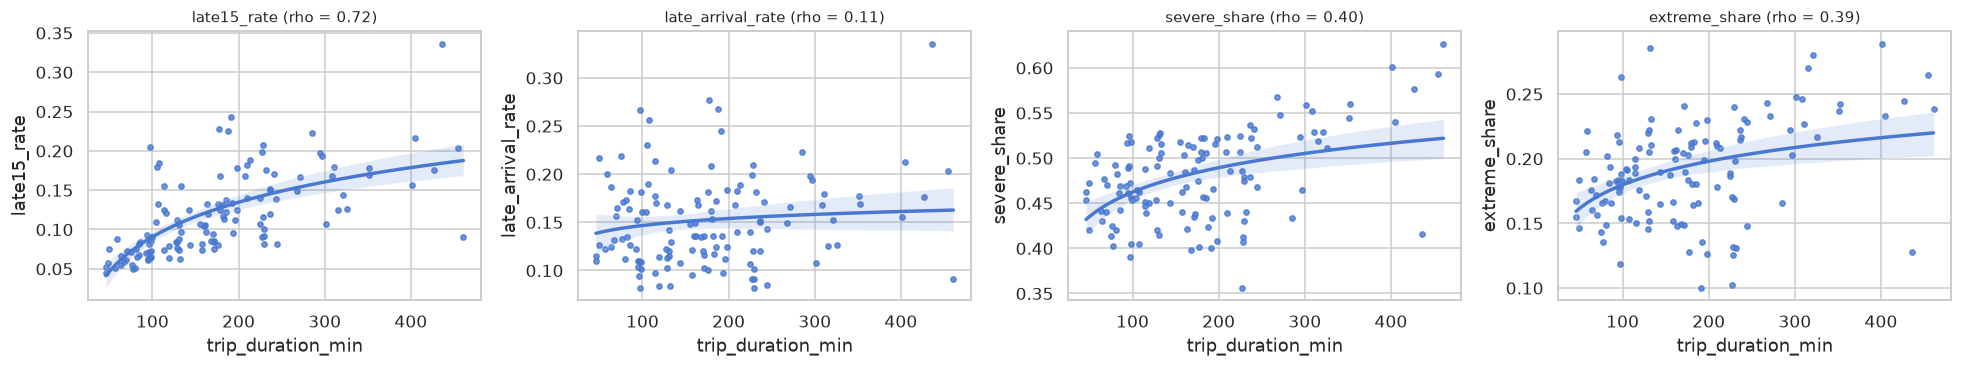

In [29]:
ALL_FEATURES = sorted(
    {f for fs in FEATURE_SETS.values() for f in fs}
    | {"late30_rate", "late60_rate", "tail_ratio"}
)
corr_duration = eligible[ALL_FEATURES].corrwith(
    eligible["trip_duration_min"], method="spearman"
)
display(
    corr_duration.sort_values()
    .to_frame("spearman_with_duration")
    .style.format("{:.2f}")
    .background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)
)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(
    axes,
    ["late15_rate", "late_arrival_rate", "severe_share", "extreme_share"],
    strict=True,
):
    sns.regplot(
        data=eligible,
        x="trip_duration_min",
        y=col,
        logx=True,
        scatter_kws={"s": 12},
        ax=ax,
    )
    ax.set_title(f"{col} (rho = {corr_duration[col]:.2f})", fontsize=10)
plt.tight_layout()
plt.show()

📌 **La durée du trajet, facteur de confusion n° 1**

| Indicateur | Corrélation avec la durée (Spearman) |
|---|---:|
| `late15_rate` (seuil fixe de 15 min) | **0,72** |
| `late30_rate`, `late60_rate`, `volatility` | **0,78 à 0,79** |
| `chronicity` | **0,70** |
| `severe_share`, `extreme_share` | 0,40 / 0,39 |
| `cancellation_rate` | 0,13 |
| `late_arrival_rate` (seuil composite SNCF) | **0,11** |
| `volatility_cv` (volatilité relative) | **0,02** |
| `mean_delay_when_late`, `severe_ratio` (composites) | **0,88 / 0,90** |

**Ce que montrent les nuages de points** : la part de trains à plus de 15 min passe d'environ
**5 % pour un trajet d'une heure à environ 19 % pour sept heures**, selon une courbe régulière.
Ce n'est pas que les longues liaisons sont « mal gérées » : un long trajet offre simplement
**plus d'occasions** d'accumuler 15 minutes de retard (**effet d'exposition**).

Avant, on pensait que les seuils fixes rendaient les liaisons comparables entre elles, et que le
seuil composite était biaisé. C'est plus nuancé :
- **le seuil composite neutralise justement la durée pour la fréquence** (0,11) : c'est sa raison
  d'être côté SNCF ; il ne la neutralise pas pour la gravité (0,88 et 0,90) ;
- **la volatilité relative (CV) a perdu tout lien avec la durée** (0,02, contre 0,79 pour la
  volatilité absolue) : le passage au CV était justifié.

Deux lectures légitimes, qui répondent à deux questions différentes :
- **« expérience voyageur »** (sans ajustement) : *quelle est ma probabilité d'arriver avec plus de
  15 min de retard ?* En absolu, les longues liaisons sont moins ponctuelles ;
- **« qualité d'exploitation à durée égale »** (avec ajustement) : *cette liaison fait-elle mieux ou
  moins bien que les autres liaisons de même longueur ?*

L'app doit proposer les deux, en expliquant la différence.

In [30]:
FEATURES = FEATURE_SETS[FEATURE_SET]
if ADJUST_DURATION:
    eligible, slopes = adjust_for_duration(eligible, FEATURES)
    print("Slopes (change per +1 in ln(duration)):")
    display(slopes.round(4).to_frame())
after = eligible[FEATURES].corrwith(eligible["trip_duration_min"], method="spearman")
print("Spearman with duration after adjustment:")
after.round(2)

Slopes (change per +1 in ln(duration)):


,slope_per_log_minute
cancellation_rate,0.0019
late15_rate,0.0636
severe_share,0.0391
extreme_share,0.0263
volatility_cv,0.0473


Spearman with duration after adjustment:


cancellation_rate   -0.0600
late15_rate         -0.0100
severe_share         0.0200
extreme_share        0.1000
volatility_cv       -0.2200
dtype: float64

📌 **Ce que l'ajustement a donné** : après correction, toutes les corrélations avec la durée sont
proches de zéro (entre −0,06 et 0,10), **sauf `volatility_cv`, à −0,22**.

C'est une leçon utile. `volatility_cv` n'était **pas** liée à la durée avant ajustement (0,02),
mais la régression linéaire a quand même estimé une petite pente ; en la retirant, on a **créé** un
lien négatif artificiel. **Règle à retenir : on n'ajuste que les variables qui dépendent vraiment
de la durée** (|ρ| > 0,3). Dans l'app, l'ajustement devrait s'appliquer variable par variable,
pas en bloc.

Si un jour une corrélation restait élevée après ajustement, cela voudrait dire que la relation
n'est pas linéaire en $\ln D$. Une variante est alors de clusteriser **par classe de durée**
(< 1 h 30, 1 h 30 à 3 h, > 3 h, les classes de la SNCF).

## II.4 Distributions et redondance

Deux variables corrélées à |ρ| > 0,8 mesurent presque la même chose : les garder toutes les
deux revient à **doubler le poids** de cette dimension dans la distance euclidienne.
On compare Pearson (linéaire) et Spearman (rangs) : un écart signale non-linéarité ou extrêmes.

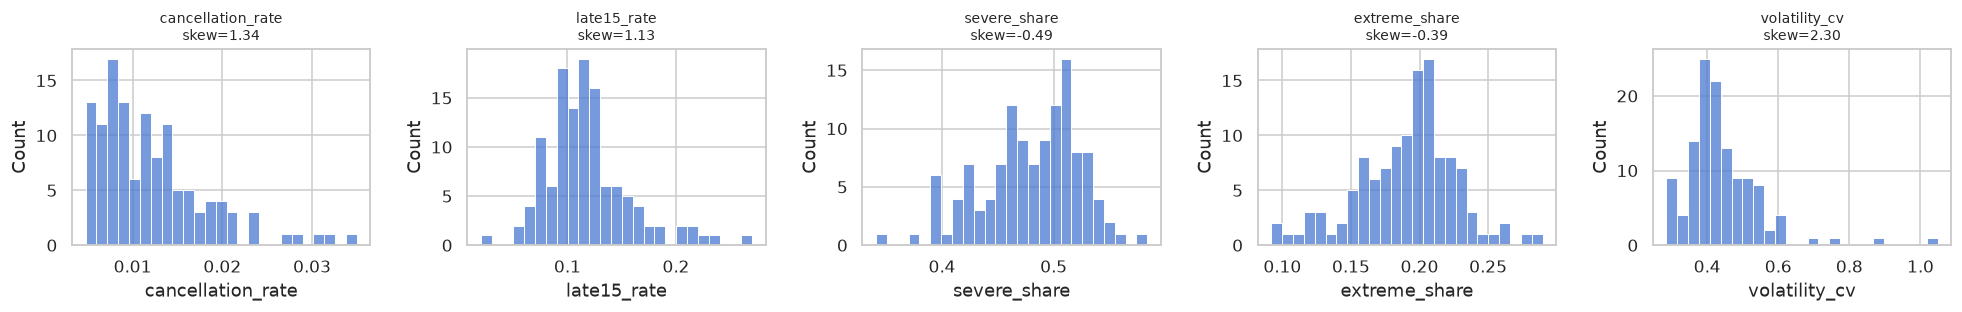

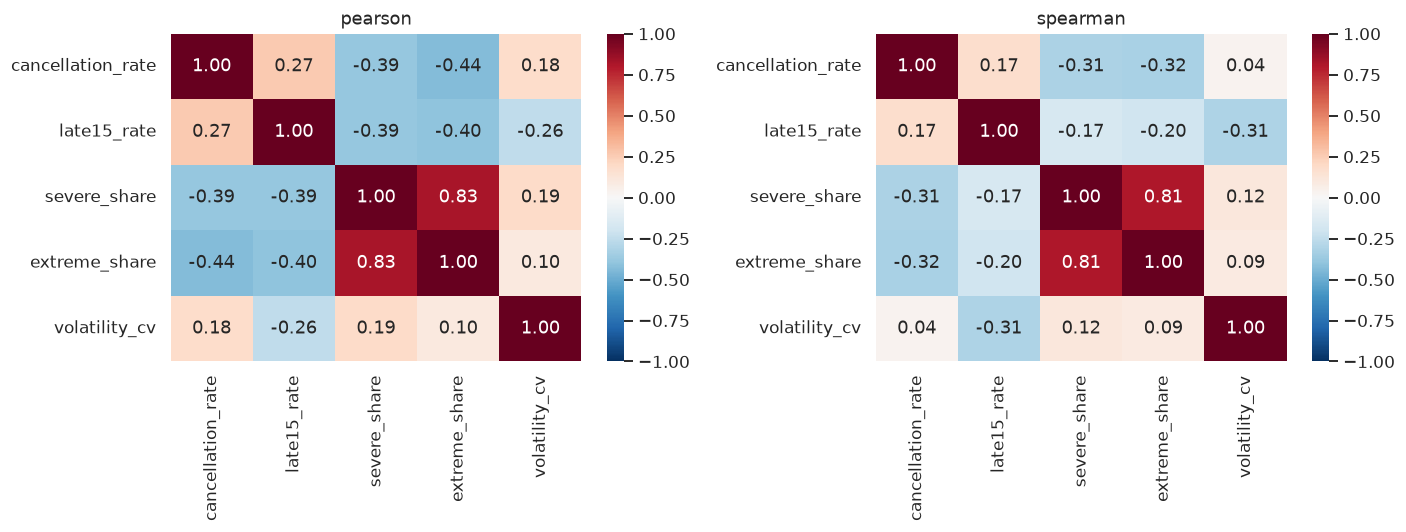

✅ No redundant pair (|rho| > 0.85) in the chosen feature set


,late15_rate,late30_rate,late60_rate,severe_share,extreme_share,tail_ratio
late15_rate,1.0000,0.5500,0.4500,-0.1700,-0.2000,-0.1800
late30_rate,0.5500,1.0000,0.9600,0.0400,0.0600,0.2200
late60_rate,0.4500,0.9600,1.0000,0.1600,0.2800,0.4500
severe_share,-0.1700,0.0400,0.1600,1.0000,0.8100,0.5100
extreme_share,-0.2000,0.0600,0.2800,0.8100,1.0000,0.8700
tail_ratio,-0.1800,0.2200,0.4500,0.5100,0.8700,1.0000


In [31]:
Xdf = eligible[FEATURES]

fig, axes = plt.subplots(1, len(FEATURES), figsize=(18, 3))
for ax, col in zip(axes, FEATURES, strict=True):
    sns.histplot(Xdf[col], bins=25, ax=ax)
    ax.set_title(f"{col}\nskew={Xdf[col].skew():.2f}", fontsize=9)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ["pearson", "spearman"], strict=True):
    sns.heatmap(
        Xdf.corr(method=method),
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        ax=ax,
    )
    ax.set_title(method)
plt.tight_layout()
plt.show()

# Automatic redundancy alert on the chosen feature set
rho = Xdf.corr("spearman").abs().where(~np.eye(len(FEATURES), dtype=bool)).stack()
redundant = rho[rho > 0.85]
if len(redundant):
    print("⚠️ Redundant pairs (|rho| > 0.85) — keep only one of each:")
    print(redundant.iloc[::2].round(2).to_string())
else:
    print("✅ No redundant pair (|rho| > 0.85) in the chosen feature set")

# Redundancy check of the unconditional 30/60 rates against late15
# (why they are not in v3)
eligible[
    [
        "late15_rate",
        "late30_rate",
        "late60_rate",
        "severe_share",
        "extreme_share",
        "tail_ratio",
    ]
].corr("spearman").round(2)

📌 **La redondance, avant et maintenant**

**Avant (jeu `fixed`)**, trois variables mesuraient la même chose :

| Paire (Spearman) | ρ |
|---|---:|
| `late15_rate` – `chronicity` | 0,98 |
| `late15_rate` – `volatility` | 0,92 |
| `volatility` – `chronicity` | 0,88 |

Dans la distance euclidienne, la fréquence pesait donc trois fois plus que la gravité et les
annulations, et K-means coupait le long de la fréquence, c'est-à-dire en grande partie le long
de la durée.

**Maintenant (jeu `v3`, ajusté)** : l'alerte automatique ne trouve **aucune paire au-dessus de
0,85**. Le dernier tableau confirme les choix :
- `late30_rate` et `late60_rate` sont redondants entre eux (0,96) : on a eu raison de ne pas les
  mettre dans le clustering ;
- les parts conditionnelles sont presque indépendantes de la fréquence (−0,17 et −0,20) : elles
  apportent bien une information nouvelle.

⚠️ **Un point de vigilance** : `severe_share` et `extreme_share` sont corrélées à **0,81**, juste
sous le seuil d'alerte. Ce sont deux mesures cousines de la gravité, qui pèse donc un peu « double »
dans la distance. Cela explique en partie pourquoi l'axe principal de l'ACP (II.7 bis) est la
gravité. À tester dans l'app : un jeu `v3` sans `severe_share`.

## II.5 Mise à l'échelle

K-means minimise une distance euclidienne : sans mise à l'échelle, la variable de plus grande
variance numérique décide seule des groupes.

- **Standardisation** : $z_{ij} = \dfrac{x_{ij} - \mu_j}{\sigma_j}$ — sensible aux extrêmes et
  ne corrige pas l'asymétrie.
- **Yeo-Johnson** (`PowerTransformer`) : transformation $\psi_\lambda(x)$ choisie par maximum de
  vraisemblance pour rendre chaque variable aussi gaussienne que possible, **puis**
  standardisation. Pour $x \ge 0$ :
$$\psi_\lambda(x) = \begin{cases}\dfrac{(x+1)^\lambda - 1}{\lambda} & \lambda \ne 0\\[4pt] \ln(x+1) & \lambda = 0\end{cases}$$
  Utile ici car les taux sont asymétriques (quelques liaisons très dégradées).

In [32]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

scaler = (
    PowerTransformer(method="yeo-johnson") if SCALER == "power" else StandardScaler()
)
X = scaler.fit_transform(Xdf)
pd.DataFrame(
    {
        "skew_before": Xdf.skew(),
        "skew_after": pd.DataFrame(X, columns=FEATURES).skew().values,
    }
)

,skew_before,skew_after
cancellation_rate,1.3387,0.1647
late15_rate,1.1250,-0.0697
severe_share,-0.4917,-0.0260
extreme_share,-0.3938,0.0237
volatility_cv,2.2987,-0.0186


📌 **À retenir** — la transformation Yeo-Johnson ramène toutes les asymétries sous 0,2 en valeur
absolue (par exemple, la volatilité relative passe de 2,30 à −0,02, et les annulations de 1,34 à
0,16). Sans elle, quelques liaisons très dégradées dicteraient la position des centres de K-means.

## II.6 Choix du nombre de profils $k$

**K-means** cherche $k$ centres $\mu_1, \dots, \mu_k$ minimisant l'**inertie** intra-classe :
$$\min_{C_1,\dots,C_k}\; \sum_{j=1}^{k}\sum_{i \in C_j}\lVert x_i - \mu_j\rVert^2$$
L'inertie diminue toujours quand $k$ augmente : on cherche le « coude ».

**Silhouette** d'une liaison $i$, avec $a(i)$ = distance moyenne aux membres de son cluster et
$b(i)$ = distance moyenne au cluster voisin le plus proche :
$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} \in [-1, 1]$$
Repères usuels de la moyenne : $> 0{,}5$ structure nette ; $0{,}25$–$0{,}5$ structure moyenne
(groupes qui se chevauchent) ; $< 0{,}25$ structure faible.

Critère supplémentaire : la **taille du plus petit groupe** (un « profil » de 2 liaisons est un
outlier, pas un profil).

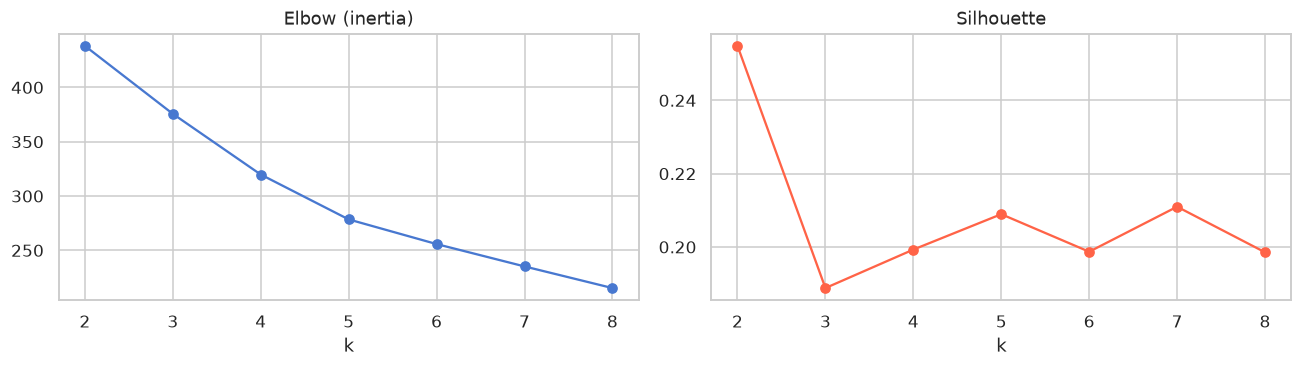

k = 2


,inertia,silhouette,smallest_cluster
k,,,
2,438.1719,0.2548,49
3,375.6171,0.1888,24
4,319.7445,0.1993,13
5,278.4536,0.2089,11
6,255.7444,0.1987,8
7,235.1698,0.2110,7
8,215.2550,0.1985,8


In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append(
        {
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X, km.labels_),
            "smallest_cluster": np.bincount(km.labels_).min(),
        }
    )
k_table = pd.DataFrame(rows).set_index("k")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
k_table["inertia"].plot(marker="o", ax=ax1, title="Elbow (inertia)")
k_table["silhouette"].plot(marker="o", ax=ax2, color="tomato", title="Silhouette")
plt.tight_layout()
plt.show()

valid = k_table[k_table["smallest_cluster"] >= 3]
K_FINAL = K or int(valid["silhouette"].idxmax())
print(f"k = {K_FINAL}")
k_table

📌 **Combien de profils ?**

| k | silhouette | plus petit groupe |
|---|---:|---:|
| **2** | **0,255** | 49 |
| 3 | 0,189 | 24 |
| 4 | 0,199 | 13 |
| 5 | 0,209 | 11 |

- **k = 2 est retenu**, mais avec une silhouette de 0,26, la structure est **faible** : les groupes
  se chevauchent largement.
- **Pourquoi la silhouette a baissé** (0,39 avant) : on a retiré les deux choses qui rendaient le
  découpage « facile » mais hors sujet, à savoir la séparation courtes / longues et la variable
  comptée trois fois. **Une silhouette plus basse sur des variables pertinentes vaut mieux qu'une
  silhouette haute sur une variable parasite.**
- Avant, on obtenait 3 groupes avec certaines variables et 2 avec d'autres : avec des scores aussi
  proches, le « meilleur k » est en partie un **choix d'interprétation**. D'où l'intérêt de faire
  varier *k* dans l'app, en regardant la stabilité.

## II.7 Ajustement, réordonnancement et nommage **à partir des données**

Deux corrections :
1. on **réordonne** les clusters par fréquence de retard croissante (0 = le plus ponctuel) ;
2. on **nomme** chaque cluster par une règle explicite comparant son centroïde à la liaison
   médiane, sur deux axes : fréquence et sévérité. Les noms restent à valider à la lecture.

In [34]:
km = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEED).fit(X)
freq_col = "late_arrival_rate" if FEATURE_SET == "composite" else "late15_rate"
sev_col = "severe_ratio" if FEATURE_SET == "composite" else "severe_share"

# 1. Reorder labels by increasing delay frequency
order = Xdf.groupby(km.labels_)[freq_col].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
eligible["cluster"] = [relabel[label] for label in km.labels_]

# 2. Name clusters from their centroid vs the median route
#    (on the scaled matrix so that adjusted features centred on 0 are handled correctly)
Z = pd.DataFrame(X, columns=FEATURES, index=eligible.index)
z_centroids_raw = Z.groupby(eligible["cluster"]).mean()
centroids = eligible.groupby("cluster")[FEATURES].mean()
TOL_Z = 0.25  # in standard deviations


def level(z: float) -> str:
    """'high', 'low' or 'mid' relative to the typical route (z = 0)."""
    return "high" if z > TOL_Z else "low" if z < -TOL_Z else "mid"


def name_profile(zc: pd.Series) -> str:
    """Rule-based archetype name for one scaled centroid."""
    f, s = level(zc[freq_col]), level(zc[sev_col])
    name = (
        "Retards chroniques"
        if f == "high" and s == "high"
        else "Retards fréquents mais courts"
        if f == "high"
        else "Retards rares mais sévères"
        if s == "high"
        else "Fiables"
        if f == "low"
        else "Dans la moyenne"
    )
    if zc["cancellation_rate"] > 0.5:
        name += " (+ annulations)"
    return name


names = {k: f"{k} · {name_profile(zc)}" for k, zc in z_centroids_raw.iterrows()}
eligible["profile"] = eligible["cluster"].map(names)
centroids.index = centroids.index.map(names)
display(centroids.assign(n_routes=eligible["profile"].value_counts()))

,cancellation_rate,late15_rate,severe_share,extreme_share,volatility_cv,n_routes
cluster,,,,,,
0 · Retards rares mais sévères,0.0097,0.1069,0.5056,0.2118,0.4588,74
1 · Retards fréquents mais courts (+ annulations),0.0158,0.1344,0.4388,0.1597,0.4160,49


📌 **Les deux profils** (valeurs ramenées à la durée moyenne du réseau)

| | Groupe 0 (74 liaisons) | Groupe 1 (49 liaisons) |
|---|---:|---:|
| Annulations | 0,97 % | **1,58 %** |
| Retards > 15 min | 10,7 % | **13,4 %** |
| Parmi eux, > 30 min | **51 %** | 44 % |
| Parmi eux, > 60 min | **21 %** | 16 % |
| Volatilité relative | 0,46 | 0,42 |

Avant, les deux groupes ne différaient que par la fréquence des retards (gravité identique : 0,46
contre 0,49). Maintenant, **ils s'opposent sur un arbitrage** :
- le **groupe 1** est **plus souvent** en retard et annule davantage, mais ses retards sont
  **moins longs** ;
- le **groupe 0** est **moins souvent** en retard, mais quand il l'est, c'est **plus grave** :
  un retard sur cinq dépasse une heure.

⚠️ **Les noms automatiques exagèrent** : « rares » désigne 10,7 % contre 13,4 %, ce qui n'est pas
rare en absolu. Pour l'app grand public, des noms plus justes seraient : **« moins souvent en
retard, mais plus longtemps »** et **« plus souvent en retard, mais moins longtemps »**.

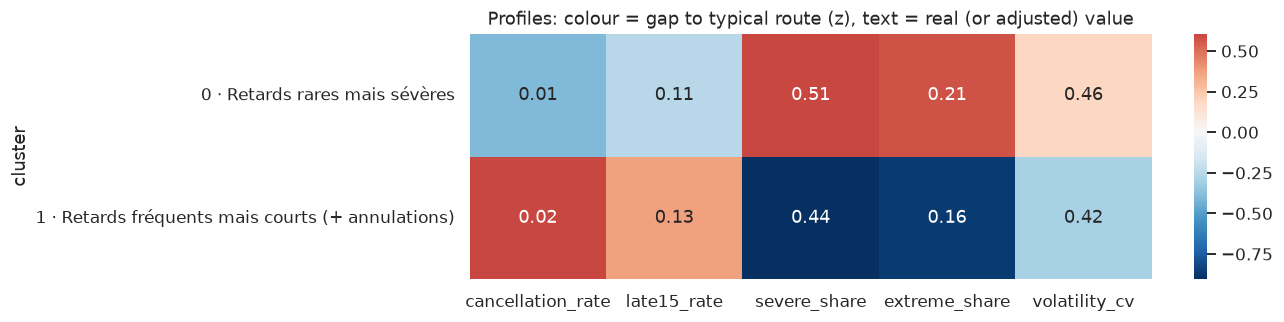

In [35]:
# Standardised centroids: what distinguishes each profile (0 = typical route)
z_centroids = z_centroids_raw.copy()
z_centroids.index = z_centroids.index.map(names)
plt.figure(figsize=(10, 0.7 * K_FINAL + 1.5))
sns.heatmap(
    z_centroids,
    annot=centroids.map(lambda v: f"{v:.2f}"),
    fmt="",
    cmap="RdBu_r",
    center=0,
)
plt.title(
    "Profiles: colour = gap to typical route (z), text = real (or adjusted) value"
)
plt.show()

## II.7 bis — ACP et cercle des corrélations

**Lire un cercle des corrélations** (il accompagne toute ACP)
- Chaque flèche est une variable ; ses coordonnées sont ses **corrélations** avec PC1 et PC2.
- **Longueur** : proche du cercle = variable bien représentée par le plan ; flèche courte = la
  variable « vit » surtout sur d'autres axes, ne pas l'interpréter ici.
- **Angle entre deux flèches** : petit = variables corrélées positivement ; ≈ 90° = indépendantes ;
  ≈ 180° = corrélées négativement.
- **Lien avec le nuage** : une liaison placée dans la direction d'une flèche a une valeur élevée de
  cette variable ; à l'opposé, une valeur faible.

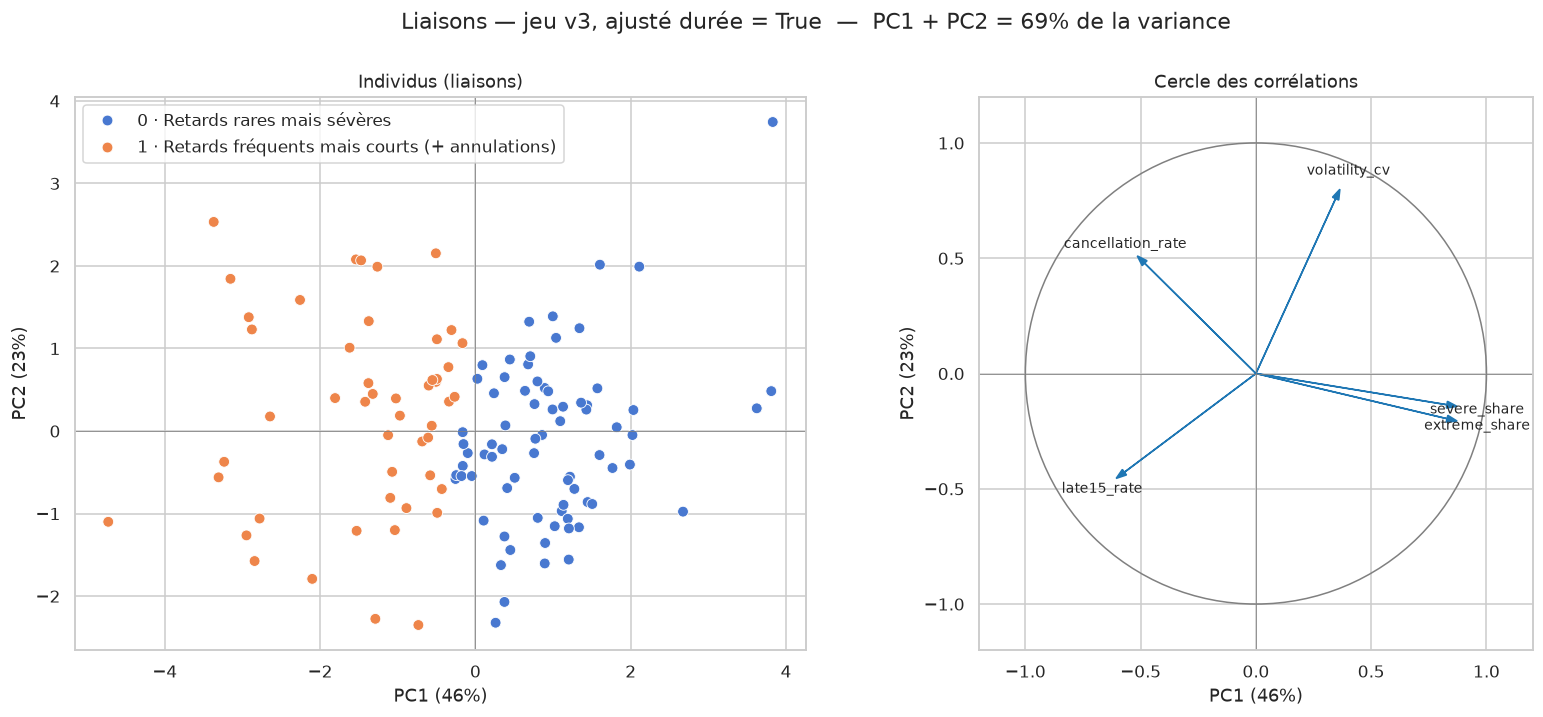

,corr_PC1,corr_PC2
cancellation_rate,-0.5100,0.5100
late15_rate,-0.6100,-0.4600
severe_share,0.8700,-0.1400
extreme_share,0.8700,-0.2100
volatility_cv,0.3600,0.8000


In [36]:
circle = pca_with_circle(
    X,
    FEATURES,
    labels=eligible["profile"].values,
    title=f"Liaisons — jeu {FEATURE_SET}, ajusté durée = {ADJUST_DURATION}",
)
circle

📌 **Lecture de l'ACP** (69 % de la variance sur le plan)

- **Axe 1 (46 %) = gravité contre fréquence.** À droite, `severe_share` et `extreme_share` (0,87
  toutes les deux). À gauche, `late15_rate` (−0,61) et `cancellation_rate` (−0,51). Une liaison à
  droite a des retards rares mais longs ; à gauche, fréquents mais courts, avec plus
  d'annulations. C'est l'arbitrage décrit plus haut.
- **Axe 2 (23 %) = instabilité.** En haut, `volatility_cv` (0,80) et les annulations (0,51) ; en
  bas, la fréquence (−0,46). En haut, des liaisons au comportement irrégulier d'un mois à l'autre ;
  en bas, des retards réguliers.
- **Les deux groupes se séparent le long de l'axe 1, sans vide entre eux** : ils se touchent
  autour de 0. C'est un **continuum** que K-means coupe en deux, pas deux familles distinctes.
- **Une liaison isolée** en haut à droite (très grave et très instable) : un bon candidat pour
  l'encadré « liaisons atypiques » de l'app (repérable avec HDBSCAN).

Avant, l'axe 1 (58 %) n'était que la fréquence (le triplet redondant), et la gravité était reléguée
à l'axe 2 : le clustering l'ignorait.

In [37]:
for profile, group in eligible.sort_values("trains_run_total", ascending=False).groupby(
    "profile"
):
    print(f"\n{profile} ({len(group)} routes)")
    print("   " + "\n   ".join(group.index[:6]))


0 · Retards rares mais sévères (74 routes)
   PARIS MONTPARNASSE → RENNES
   LYON PART DIEU → PARIS LYON
   PARIS LYON → LYON PART DIEU
   PARIS NORD → LILLE
   NANTES → PARIS MONTPARNASSE
   PARIS MONTPARNASSE → NANTES

1 · Retards fréquents mais courts (+ annulations) (49 routes)
   BORDEAUX ST JEAN → PARIS MONTPARNASSE
   PARIS MONTPARNASSE → BORDEAUX ST JEAN
   RENNES → PARIS MONTPARNASSE
   LILLE → PARIS NORD
   STRASBOURG → PARIS EST
   LYON PART DIEU → MARSEILLE ST CHARLES


## II.8 Le profil reflète-t-il un comportement ou la durée du trajet ?

On refait le clustering avec chaque jeu d'indicateurs, avec et sans ajustement, et on mesure ce
que les groupes « expliquent » grâce au **rapport de corrélation** $\eta^2$ : la part de la
variance d'une variable expliquée par l'appartenance au groupe (0 = rien, 1 = tout).

📌 **Une observation en passant, à approfondir** : dans les listes ci-dessus, le sens du trajet
compte. Paris → Rennes et Paris → Lille sont dans le groupe 0, mais Rennes → Paris et Lille → Paris
dans le groupe 1 ; Bordeaux ↔ Paris est dans le groupe 1 dans les deux sens. Hypothèse : les
arrivées vers les grandes gares parisiennes, saturées, subissent des retards plus fréquents.
C'est exactement le sujet de la Q2 (gares « responsables » contre gares qui « subissent »).

,eta2_duration,eta2_late15,eta2_severity,eta2_extreme
composite,0.42,0.63,0.06,0.03
composite + adj,0.00,0.05,0.24,0.19
fixed,0.37,0.62,0.05,0.01
fixed + adj,0.00,0.26,0.13,0.12
v3,0.06,0.01,0.56,0.51
v3 + adj,0.02,0.04,0.51,0.49


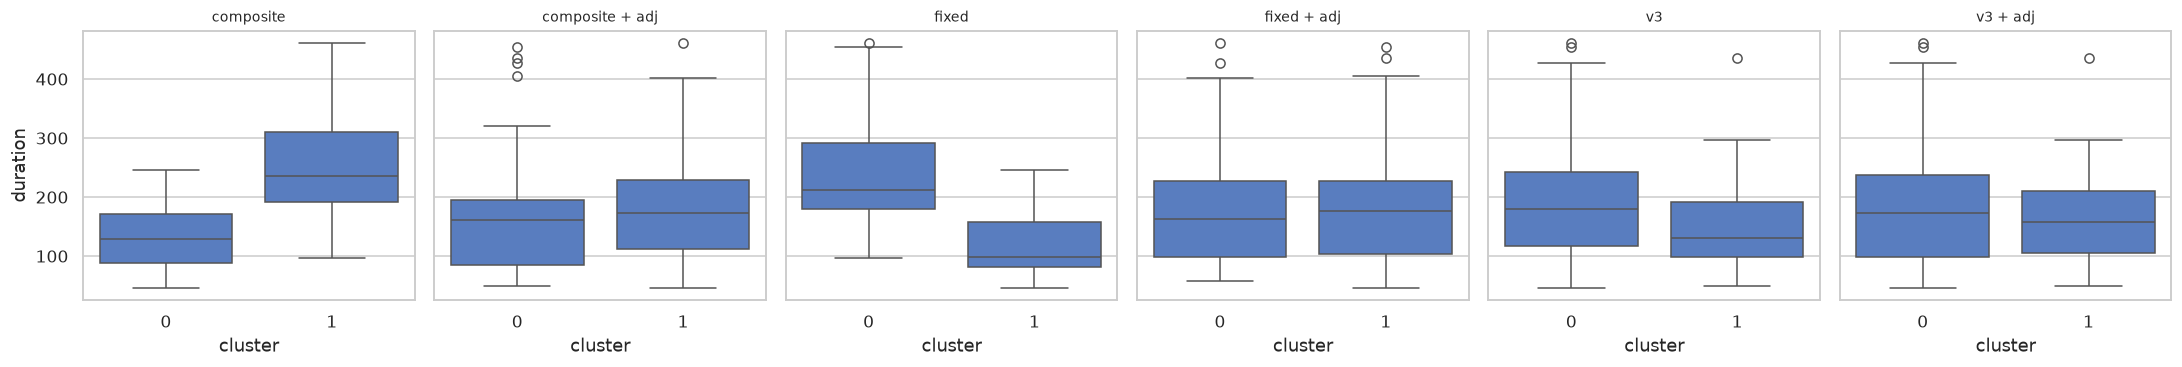

In [38]:
from sklearn.metrics import adjusted_rand_score


def prepare_matrix(
    table: pd.DataFrame, features: list[str], adjust: bool
) -> np.ndarray:
    """Optional duration adjustment, then scaling."""
    t = adjust_for_duration(table, features)[0] if adjust else table
    sc = PowerTransformer() if SCALER == "power" else StandardScaler()
    return sc.fit_transform(t[features])


def kmeans_labels(
    table: pd.DataFrame, features: list[str], k: int, adjust: bool
) -> np.ndarray:
    """K-means labels for a feature set."""
    return KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(
        prepare_matrix(table, features, adjust)
    )


base = routes[routes["n_months"] >= MIN_MONTHS]
variants = {
    f"{fs}{' + adj' if adj else ''}": kmeans_labels(
        base, FEATURE_SETS[fs], K_FINAL, adj
    )
    for fs in ["composite", "fixed", "v3"]
    for adj in [False, True]
}
comparison = pd.DataFrame(variants, index=base.index).assign(
    duration=base["trip_duration_min"]
)
summary = pd.DataFrame(
    {
        name: {
            "eta2_duration": eta_squared(comparison["duration"], lab),
            "eta2_late15": eta_squared(base["late15_rate"], lab),
            "eta2_severity": eta_squared(base["severe_share"], lab),
            "eta2_extreme": eta_squared(base["extreme_share"], lab),
        }
        for name, lab in variants.items()
    }
).T
display(
    summary.style.format("{:.2f}").background_gradient(
        subset=["eta2_duration"], cmap="Reds"
    )
)
fig, axes = plt.subplots(1, len(variants), figsize=(20, 3.5), sharey=True)
for ax, name in zip(axes, variants, strict=True):
    sns.boxplot(data=comparison, x=name, y="duration", ax=ax)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("cluster")
plt.tight_layout()
plt.show()

📌 **Le résultat principal de la Q3**

| Variables | $\eta^2$ durée | $\eta^2$ fréquence | $\eta^2$ gravité (> 30) | $\eta^2$ gravité (> 60) |
|---|---:|---:|---:|---:|
| composite (v1) | **0,42** | 0,63 | 0,06 | 0,03 |
| fixed (v2) | **0,37** | 0,62 | 0,05 | 0,01 |
| fixed ajusté | 0,00 | 0,26 | 0,13 | 0,12 |
| **v3** | 0,06 | 0,01 | **0,56** | **0,51** |
| **v3 ajusté** | 0,02 | 0,04 | **0,51** | **0,49** |

Et les boîtes à moustaches le confirment visuellement :
- **avant (v1, v2)**, les groupes séparent nettement les durées : d'un côté des liaisons d'environ
  1 h 40, de l'autre d'environ 3 h 30. Le clustering ne faisait que **retrouver la durée** ;
- **maintenant (v3)**, les deux groupes ont **les mêmes durées**, et ils sont séparés par la
  **gravité** des retards (plus de la moitié de sa variance est expliquée).

**Deux remarques importantes**
- Le jeu `v3` est **déjà presque indépendant de la durée sans ajustement** (η² = 0,06), parce que
  les parts conditionnelles et la volatilité relative sont, par construction, peu liées à la
  longueur du trajet. **Le bon choix des variables a fait l'essentiel du travail** ; l'ajustement
  affine.
- Les groupes `v3` ne disent presque rien de la fréquence brute (η² = 0,01) : pour classer les
  liaisons selon la fréquence de leurs retards, c'est le **score de fiabilité** (Q4) qui est le bon
  outil, pas ce clustering.

## II.9 Robustesse : trois tests qui ne mesurent pas la même chose

| Test | Ce qu'on fait varier | Question posée |
|---|---|---|
| Graines | l'initialisation de K-means | l'algorithme converge-t-il toujours vers la même solution ? |
| Rééchantillonnage | les **liaisons** (80 % tirées au hasard, 30 fois) | les groupes tiennent-ils si les données changent un peu ? |
| Permutation | on **mélange** chaque colonne indépendamment | la structure est-elle meilleure que sur des données sans structure ? |

La v1 ne faisait que le premier, qui est le plus faible : un ARI de 1 entre graines prouve
seulement que l'optimisation est stable, pas que les profils existent.

L'**indice de Rand ajusté** (ARI) compare deux partitions : 1 = identiques, ≈ 0 = accord pas
meilleur que le hasard.

Seeds         : mean ARI = 0.94
Resampling    : median ARI = 0.92 (min 0.44)
Permutation   : real silhouette 0.255 vs shuffled max 0.177


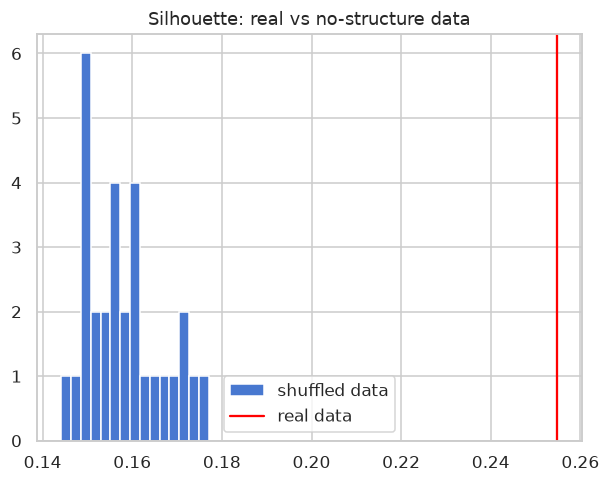

In [39]:
rng = np.random.default_rng(SEED)
ref = eligible["cluster"].values

ari_seeds = [
    adjusted_rand_score(ref, KMeans(K_FINAL, n_init=1, random_state=s).fit_predict(X))
    for s in range(20)
]

ari_boot = []
for _ in range(30):
    idx = np.sort(rng.choice(len(X), int(0.8 * len(X)), replace=False))
    sc = PowerTransformer() if SCALER == "power" else StandardScaler()
    sub = sc.fit_transform(Xdf.iloc[idx])
    ari_boot.append(
        adjusted_rand_score(
            ref[idx], KMeans(K_FINAL, n_init=20, random_state=SEED).fit_predict(sub)
        )
    )

real_sil = silhouette_score(X, ref)
null_sil = []
for _ in range(30):
    shuffled = np.column_stack([rng.permutation(col) for col in Xdf.values.T])
    sc = PowerTransformer() if SCALER == "power" else StandardScaler()
    Xs = sc.fit_transform(shuffled)
    null_sil.append(
        silhouette_score(
            Xs, KMeans(K_FINAL, n_init=10, random_state=SEED).fit_predict(Xs)
        )
    )

print(f"Seeds         : mean ARI = {np.mean(ari_seeds):.2f}")
print(
    f"Resampling    : median ARI = {np.median(ari_boot):.2f}"
    f" (min {np.min(ari_boot):.2f})"
)
print(
    f"Permutation   : real silhouette {real_sil:.3f}"
    f" vs shuffled max {np.max(null_sil):.3f}"
)
plt.hist(null_sil, bins=15, label="shuffled data")
plt.axvline(real_sil, color="red", label="real data")
plt.legend()
plt.title("Silhouette: real vs no-structure data")
plt.show()

📌 **La structure est-elle solide ?**

| Test | Résultat | Lecture |
|---|---|---|
| Graines | ARI moyen 0,94 | L'algorithme retombe presque toujours sur la même solution |
| Rééchantillonnage (80 % des liaisons, 30 fois) | ARI médian **0,92**, minimum **0,44** | Le découpage tient en général, mais certains tirages le réorganisent : il y a des **liaisons frontières** |
| Permutation | silhouette réelle **0,255** contre 0,177 au maximum sur données mélangées | La structure n'est **pas due au hasard**… mais l'écart est modeste |

Avant, ces tests étaient encore plus favorables (silhouette 0,39, ARI 0,92)… alors que les groupes
retrouvaient surtout la durée. Rappel : **stable ne veut pas dire pertinent**. La robustesse dit
« ce découpage n'est pas un accident », pas « ce découpage répond à la question ». C'est le travail
sur les variables (II.3, II.4, II.8) qui garantit la pertinence.

## II.10 — Impact des mois exceptionnels (et des décisions de nettoyage)

On garde **tout le reste fixe** (indicateurs, ajustement, mise à l'échelle, *k*) et on ne fait
varier que la règle d'exclusion :
- `none` : aucun mois retiré ;
- `known` : les événements documentés (grèves, confinements) ;
- `data` : les mois détectés automatiquement (pour comparaison).

On mesure : l'accord des partitions (ARI vs `known`), le déplacement moyen des indicateurs (en
points de pourcentage) et le nombre de liaisons qui changent de groupe.

In [40]:
def run_variant(months: list[str]) -> tuple[pd.DataFrame, np.ndarray]:
    """Features and K-means labels after removing `months`."""
    d = data[~data["date"].astype(str).isin(months)]
    t = build_route_features(d)
    t = t[t["n_months"] >= MIN_MONTHS]
    return t, kmeans_labels(t, FEATURES, K_FINAL, ADJUST_DURATION)


runs = {
    name: run_variant(m)
    for name, m in {"none": [], "known": KNOWN_MONTHS, "data": DETECTED_MONTHS}.items()
}
ref_t, ref_l = runs["known"]
rows = []
for name, (t, lab) in runs.items():
    common = ref_t.index.intersection(t.index)
    a = pd.Series(lab, index=t.index)[common]
    b = pd.Series(ref_l, index=ref_t.index)[common]
    rows.append(
        {
            "variant": name,
            "months excluded": {
                "none": 0,
                "known": len(KNOWN_MONTHS),
                "data": len(DETECTED_MONTHS),
            }[name],
            "routes": len(t),
            "ARI vs known": adjusted_rand_score(b, a),
            "mean |Δ late15| (pts)": 100
            * (t.loc[common, "late15_rate"] - ref_t.loc[common, "late15_rate"])
            .abs()
            .mean(),
            "mean |Δ cancellation| (pts)": 100
            * (
                t.loc[common, "cancellation_rate"]
                - ref_t.loc[common, "cancellation_rate"]
            )
            .abs()
            .mean(),
        }
    )
pd.DataFrame(rows).set_index("variant").round(3)

,months excluded,routes,ARI vs known,mean |Δ late15| (pts),mean |Δ cancellation| (pts)
variant,,,,,
none,0,123,0.6190,0.1940,1.9500
known,20,123,1.0000,0.0000,0.0000
data,25,123,0.8730,0.4430,0.1700


📌 **L'exclusion des grèves et confinements change-t-elle les profils ? Oui, nettement.**

| Variante | Mois exclus | ARI avec « événements documentés » | Écart moyen retards > 15 min | Écart moyen annulations |
|---|---:|---:|---:|---:|
| Aucune exclusion | 0 | **0,62** | 0,19 pt | **1,95 pt** |
| Événements documentés | 20 | 1,00 | — | — |
| Détection automatique | 25 | 0,87 | 0,44 pt | 0,17 pt |

- **Garder les mois de crise bouleverse les groupes** (accord de 0,62 seulement). Le mécanisme est
  clair : ces mois touchent surtout les **annulations** (écart moyen de 2 points, contre 0,2 point
  pour les retards). Comme les annulations font partie des variables, les profils refléteraient
  alors **l'exposition de chaque axe aux grèves**, pas sa qualité d'exploitation habituelle.
  L'exclusion des événements documentés est donc justifiée, et **c'est un choix qui compte** :
  l'app doit le montrer.
- **La détection automatique** donne des profils proches (0,87), mais elle retire aussi des mois
  simplement mauvais : les retards baissent alors artificiellement (écart de 0,44 point). C'est le
  biais attendu.
- Ces résultats incluent encore février 2020 dans la liste ; le retirer ne change qu'un mois sur 20.

## II.11 — Conclusions

### La réponse à la Q3

**Oui, on peut regrouper les liaisons, mais pas en « familles » naturelles.** Les liaisons TGV
forment un **continuum**. Le découpage le plus pertinent, une fois retirés l'effet de la durée et
les variables redondantes, oppose deux manières d'être peu fiable :

| | « Plus souvent en retard, mais moins longtemps » | « Moins souvent en retard, mais plus longtemps » |
|---|---|---|
| Liaisons | 49 | 74 |
| Retards > 15 min | 13,4 % | 10,7 % |
| Parmi eux, > 60 min | 16 % | 21 % |
| Annulations | 1,6 % | 1,0 % |

Ce découpage est **stable** (ARI médian 0,92) et **meilleur que le hasard**, mais **faible**
(silhouette 0,26) : beaucoup de liaisons sont à la frontière.

### Les résultats « bonus », tout aussi importants pour l'article
1. **La durée du trajet explique une grande partie des écarts de ponctualité** : environ 5 % de
   trains à plus de 15 min de retard pour une heure de trajet, environ 19 % pour sept heures. Un
   classement « brut » des liaisons pénalise mécaniquement les longues.
2. **Le clustering précédent était trompeur** : ses groupes bien séparés n'étaient que des
   liaisons courtes et longues. C'est un bel exemple pédagogique de facteur de confusion.
3. **Le traitement des crises (grèves, confinements) change les profils** : il doit être
   explicite.
4. **Le sens du trajet semble compter** (arrivées vers Paris plus souvent en retard) : une piste
   pour la Q2.
5. **2025 est une année fragile dans la source** (trou de publication, lignes en double,
   changement de définition des retards > 30 min) : à corriger avant toute tendance (Q1).

### Limites
Données mensuelles agrégées (on décrit des liaisons, pas des trajets individuels) ; même train
compté dans plusieurs liaisons ; ajustement à la durée linéaire en $\ln D$ ; causes déclarées par
l'opérateur, non utilisées ; correction de 2025 encore à faire dans le pipeline.

### Ce qui part dans Streamlit
Tous les paramètres de ce notebook deviennent des contrôles : jeu d'indicateurs (ou sélection
libre, avec alerte de redondance), ajustement à la durée **variable par variable**, règle
d'exclusion des mois, mise à l'échelle, algorithme, *k*, seuil d'éligibilité. Pour chaque
combinaison, l'app affiche la silhouette, la stabilité, les $\eta^2$ (durée, fréquence, gravité),
l'ACP avec son cercle des corrélations, les profils avec des **noms grand public**, et une fiche
par liaison.